IPOs data from Web

    learn dataframes "stacking" (UNION ALL)
    learn about type casting
    generate new columns (simple and with function)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas_datareader as pdr
import requests

from datetime import date
from io import StringIO

In [2]:
def get_ipos_by_year(year: int) -> pd.DataFrame:
    """
    Fetch IPO data for the given year from stockanalysis.com.
    """
    url = f"https://stockanalysis.com/ipos/{year}/"
    headers = {
        'User-Agent': (
            'Mozilla/5.0 (Windows NT 10.0; Win64; x64) '
            'AppleWebKit/537.36 (KHTML, like Gecko) '
            'Chrome/58.0.3029.110 Safari/537.3'
        )
    }

    try:
        response = requests.get(url, headers=headers, timeout=10)
        response.raise_for_status()

        # Wrap HTML text in StringIO to avoid deprecation warning
        # "Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object."
        html_io = StringIO(response.text)
        tables = pd.read_html(html_io)

        if not tables:
            raise ValueError(f"No tables found for year {year}.")

        return tables[0]

    except requests.exceptions.RequestException as e:
        print(f"Request failed: {e}")
    except ValueError as ve:
        print(f"Data error: {ve}")
    except Exception as ex:
        print(f"Unexpected error: {ex}")

    return pd.DataFrame()

In [3]:
ipos_2023 = get_ipos_by_year(2023)
ipos_2023.info() 


<class 'pandas.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   IPO Date      153 non-null    str  
 1   Symbol        153 non-null    str  
 2   Company Name  153 non-null    str  
 3   IPO Price     153 non-null    str  
 4   Current       153 non-null    str  
 5   Return        153 non-null    str  
dtypes: str(6)
memory usage: 15.8 KB


In [4]:
ipos_2024 = get_ipos_by_year(2024)
ipos_2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 226 entries, 0 to 225
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   IPO Date      226 non-null    str  
 1   Symbol        226 non-null    str  
 2   Company Name  226 non-null    str  
 3   IPO Price     226 non-null    str  
 4   Current       226 non-null    str  
 5   Return        226 non-null    str  
dtypes: str(6)
memory usage: 23.4 KB


In [5]:
ipos_2025 = get_ipos_by_year(2025)
ipos_2025.info()

<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   IPO Date      350 non-null    str  
 1   Symbol        350 non-null    str  
 2   Company Name  350 non-null    str  
 3   IPO Price     350 non-null    str  
 4   Current       350 non-null    str  
 5   Return        350 non-null    str  
dtypes: str(6)
memory usage: 36.5 KB


In [6]:
ipos_2026 = get_ipos_by_year(2026)
ipos_2026.info()

<class 'pandas.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   IPO Date      249 non-null    str  
 1   Symbol        249 non-null    str  
 2   Company Name  249 non-null    str  
 3   IPO Price     249 non-null    str  
 4   Current       249 non-null    str  
 5   Return        249 non-null    str  
dtypes: str(6)
memory usage: 26.2 KB


In [7]:
# "stacking dataframes"
# pd.concat() is used to concatenate the DataFrames vertically.
# The ignore_index=True parameter ensures that the resulting DataFrame has a new index,
# ignoring the original indices of the input DataFrames.
# The stacked_df now contains the concatenated DataFrame.
stacked_ipos_df = pd.concat([ipos_2026 ,ipos_2025, ipos_2024, ipos_2023], ignore_index=True)

In [8]:
stacked_ipos_df.head(1)

,IPO Date,Symbol,Company Name,IPO Price,Current,Return
0,"Sep 25, 2026",ADRX,"ADARx Pharmaceuticals, Inc.",$17.00,$19.35,13.82%


In [9]:
len(stacked_ipos_df)

978

In [10]:
# Need to convert everything to a proper type (date, str, int, float, etc.)
stacked_ipos_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 978 entries, 0 to 977
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   IPO Date      978 non-null    str  
 1   Symbol        978 non-null    str  
 2   Company Name  978 non-null    str  
 3   IPO Price     978 non-null    str  
 4   Current       978 non-null    str  
 5   Return        978 non-null    str  
dtypes: str(6)
memory usage: 101.5 KB


In [11]:
# convert to datetime
stacked_ipos_df['IPO Date'] = pd.to_datetime(stacked_ipos_df['IPO Date'], format='mixed')

In [12]:
# Problem --> not always the columns are filled
missing_prices_df = stacked_ipos_df[stacked_ipos_df['IPO Price'].astype(str).str.find('-') >= 0]
missing_prices_df.head(5) 

,IPO Date,Symbol,Company Name,IPO Price,Current,Return
77,2026-06-10,ATLQ,JAB Acquisition Corp I,-,$9.98,-
197,2026-02-11,IPXG,Inflection Point Acquisition Corp. VII,-,$10.05,-
285,2025-11-13,NXB,NextBoat Inc.,-,$2.02,-
362,2025-09-09,ZTG,Zenta Group Company Limited,-,$1.34,-
445,2025-06-17,MENS,Jyong Biotech Ltd.,-,$2.03,-


In [13]:
# it has some missing values --> use defensive errors='coerce' (if don't have time to crack into the data errors)
#     : pd.to_numeric() function call, which will convert problematic values to NaN.
#     otherwise you'll get a ValueError: Unable to parse string "-" at position 9
stacked_ipos_df['IPO Price'] = pd.to_numeric(stacked_ipos_df['IPO Price'].str.replace('$', ''), errors='coerce')
# not sure why, but need to call it again to transform 'object' to 'float64'
# stacked_ipos_df['IPO Price'] = pd.to_numeric(stacked_ipos_df['IPO Price'])  


In [14]:
stacked_ipos_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 978 entries, 0 to 977
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   IPO Date      978 non-null    datetime64[us]
 1   Symbol        978 non-null    str           
 2   Company Name  978 non-null    str           
 3   IPO Price     949 non-null    float64       
 4   Current       978 non-null    str           
 5   Return        978 non-null    str           
dtypes: datetime64[us](1), float64(1), str(4)
memory usage: 85.0 KB


In [15]:
# Convert "Current" column
stacked_ipos_df['Current'] = pd.to_numeric(stacked_ipos_df['Current'].str.replace('$', ''), errors='coerce')

# Convert 'Return' to numeric format (percentage)
stacked_ipos_df['Return'] = pd.to_numeric(stacked_ipos_df['Return'].str.replace('%', ''), errors='coerce') / 100

In [16]:
stacked_ipos_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 978 entries, 0 to 977
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   IPO Date      978 non-null    datetime64[us]
 1   Symbol        978 non-null    str           
 2   Company Name  978 non-null    str           
 3   IPO Price     949 non-null    float64       
 4   Current       976 non-null    float64       
 5   Return        923 non-null    float64       
dtypes: datetime64[us](1), float64(3), str(2)
memory usage: 73.9 KB


In [17]:
stacked_ipos_df.head(1)

,IPO Date,Symbol,Company Name,IPO Price,Current,Return
0,2026-09-25,ADRX,"ADARx Pharmaceuticals, Inc.",17.0,19.35,0.1382


In [18]:
# simple way of checking NULLs
# (you need to understand how vector operations work .isnull() and calls chaining .isnull().sum())
stacked_ipos_df.isnull().sum()

IPO Date         0
Symbol           0
Company Name     0
IPO Price       29
Current          2
Return          55
dtype: int64

In [19]:
# Do you want to leave the record or not?
stacked_ipos_df[stacked_ipos_df.Return.isnull()]

,IPO Date,Symbol,Company Name,IPO Price,Current,Return
1,2026-09-25,BRRK,Bluerock Acquisition Corp. II,10.0,10.000,NaN
25,2026-08-07,TP,Ticketplus Ltd.,8.0,8.000,NaN
67,2026-06-23,GHXI,"Gores Holdings XI, Inc.",10.0,10.000,NaN
77,2026-06-10,ATLQ,JAB Acquisition Corp I,NaN,9.980,NaN
96,2026-05-27,DGAC,Disciplined Growth Acquisition Corporation,10.0,10.000,NaN
101,2026-05-21,OHAC,Oceanhawk Acquisition Corp,10.0,10.000,NaN
105,2026-05-15,ETSS,Energy Transition Special Opportunities,10.0,9.950,NaN
108,2026-05-15,IDAC,Iron Dome Acquisition I Corp.,10.0,10.000,NaN
129,2026-05-01,QLEP,Quantum Leap Acquisition Corp,10.0,10.000,NaN
164,2026-03-20,BWIV,Blue Water Acquisition Corp. IV,10.0,10.000,NaN


In [20]:
# now you can operate with columns as a numeric type
stacked_ipos_df['IPO Price'].mean()

np.float64(11.95331928345627)

In [21]:
# generate a new field -- SIMPLE calculation (no function needed)
stacked_ipos_df['Price Increase'] = stacked_ipos_df['Current'] - stacked_ipos_df['IPO Price']
stacked_ipos_df['Price Increase'].mean()

np.float64(2.128634635691658)

In [22]:
stacked_ipos_df.head(1)

,IPO Date,Symbol,Company Name,IPO Price,Current,Return,Price Increase
0,2026-09-25,ADRX,"ADARx Pharmaceuticals, Inc.",17.0,19.35,0.1382,2.35


In [23]:
# Descriptive Analytics of a dataset
stacked_ipos_df.describe()

,IPO Date,IPO Price,Current,Return,Price Increase
count,978,949.000000,976.000000,923.000000,947.000000
mean,2025-03-06 03:32:01.472392,11.953319,13.820187,0.018435,2.128635
min,2023-01-13 00:00:00,2.500000,0.002000,-0.999500,-46.940000
25%,2024-06-27 06:00:00,5.000000,3.120000,-0.519050,-3.048500
50%,2025-05-01 12:00:00,10.000000,10.035000,-0.001500,0.000000
75%,2026-01-08 00:00:00,14.000000,11.682500,0.085000,0.840000
max,2026-09-25 00:00:00,185.000000,364.620000,9.128300,328.620000
std,NaN,12.105664,24.433735,0.941805,19.892480


In [24]:
# some visualisation: bar chart using Plotly Express
import plotly.express as px

# Truncate to the first day in the month - for Bar names
stacked_ipos_df['Date_monthly'] = stacked_ipos_df['IPO Date'].dt.to_period('M').dt.to_timestamp()

# Count the number of deals for each month and year
monthly_deals = stacked_ipos_df['Date_monthly'].value_counts().reset_index().sort_values(by='Date_monthly')
monthly_deals.columns = ['Date_monthly', 'Number of Deals']

# Plotting the bar chart using Plotly Express
fig = px.bar(monthly_deals,
             x='Date_monthly',
             y='Number of Deals',
             labels={'Month_Year': 'Month and Year', 'Number of Deals': 'Number of Deals'},
             title='Number of IPO Deals per Month and Year',
             text='Number of Deals'
             )
fig.update_traces(textposition='outside', # Position the text outside the bars
                  textfont=dict(color='black',size=14), # Adjust the font size of the text
                  )
fig.update_layout(title_x=0.5) # Center the title

fig.show()

In [25]:
rddt_filter = stacked_ipos_df.Symbol=='RDDT'
stacked_ipos_df[rddt_filter]

,IPO Date,Symbol,Company Name,IPO Price,Current,Return,Price Increase,Date_monthly
789,2024-03-21,RDDT,"Reddit, Inc.",34.0,149.84,3.4071,115.84,2024-03-01


In [26]:
import yfinance as yf

# To be used for home assignment: 'You can notice a bump in the price after the IPO? And after that the price goes down
# You're asked to design a simple strategy to buy and hold for X days (at 'Adj.Close' price, no fees)
# Find an optimal X between 1 and 30, that delivers you a MAX mean return on ALL 2023 IPOs?
# Write down the answer X (a number between 1 and 30)

# What is the distribution of other returns 25-50-75% quantiles? Compare mean and median returns for 2023 (median may be more robust),
  # are you losing money in 25% cases (if 25% quantile returns is < 0)
  # Try the same X for all deals in 2024.  How the mean return in 2024 (out of sample data) is different from 2023 data?

# REDDIT - recent IPO
# https://finance.yahoo.com/quote/RDDT/
ticker_obj = yf.Ticker("RDDT")
reddit = ticker_obj.history(period = "max", interval = "1d")

reddit.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-21 00:00:00-04:00,152.669998,160.350006,151.740005,158.729996,5457500,0.0,0.0
2026-09-22 00:00:00-04:00,161.279999,161.669998,152.330002,155.669998,4252600,0.0,0.0
2026-09-23 00:00:00-04:00,154.009995,154.940002,147.770004,151.979996,4569700,0.0,0.0
2026-09-24 00:00:00-04:00,151.500000,153.880005,150.199997,152.720001,3256700,0.0,0.0
2026-09-25 00:00:00-04:00,152.729996,154.759995,149.820007,149.839996,2869300,0.0,0.0


<Axes: title={'center': "Reddit's (RDDT) price after the IPO"}, xlabel='Date'>

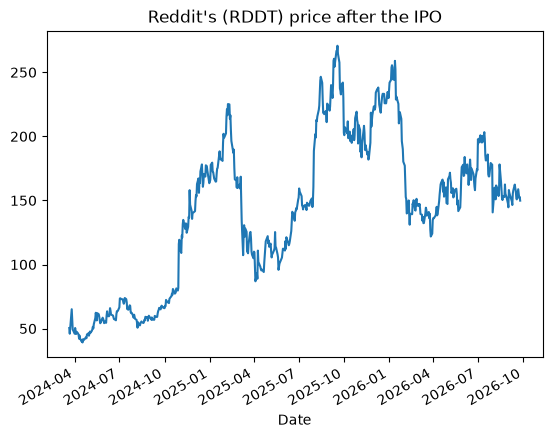

In [27]:
reddit['Close'].plot.line(title='Reddit\'s (RDDT) price after the IPO')

## Home assignment: buy an IPO and hold it for X days

Strategy: buy at the close of the first trading day and sell X trading days later (adjusted close, no fees).
Return for one IPO = `price[X] / price[0] - 1`.

Caveat: Yahoo Finance has no data for delisted tickers, so these results suffer from **survivorship bias**
(the worst IPOs often get delisted, which makes the real returns even worse than what we measure here).

In [28]:
import logging

# yfinance logs an error for every delisted ticker -- silence it
logging.getLogger('yfinance').setLevel(logging.CRITICAL)


def get_post_ipo_prices(ipos_df: pd.DataFrame, days_after: int = 70) -> dict[str, pd.Series]:
    """
    Download daily adjusted close prices starting at the IPO date for every symbol.
    Returns {symbol: Series of prices indexed by trading day number (0 = IPO day)}.
    """
    prices = {}
    for symbol, ipo_date in zip(ipos_df['Symbol'], ipos_df['IPO Date']):
        try:
            # auto_adjust=True --> 'Close' is the adjusted close
            history = yf.Ticker(symbol).history(start=ipo_date,
                                                end=ipo_date + pd.Timedelta(days=days_after),
                                                interval='1d',
                                                auto_adjust=True)
        except Exception:
            continue
        if history.empty:
            continue
        # skip tickers whose first trading day is far from the IPO date (reused symbols, bad data)
        first_day = history.index[0].tz_localize(None).normalize()

        if (first_day - ipo_date).days > 7:
            continue

        prices[symbol] = history['Close'].reset_index(drop=True)
    return prices

In [29]:
ipos_2023_df = stacked_ipos_df[stacked_ipos_df['IPO Date'].dt.year == 2023]
ipos_2024_df = stacked_ipos_df[stacked_ipos_df['IPO Date'].dt.year == 2024]

# takes a few minutes: one request per IPO
prices_2023 = get_post_ipo_prices(ipos_2023_df)
prices_2024 = get_post_ipo_prices(ipos_2024_df)

print(f"2023: {len(prices_2023)} of {len(ipos_2023_df)} IPOs have price data")
print(f"2024: {len(prices_2024)} of {len(ipos_2024_df)} IPOs have price data")

2023: 99 of 153 IPOs have price data
2024: 159 of 226 IPOs have price data


In [30]:
def holding_returns(prices: dict[str, pd.Series], x: int) -> pd.Series:
    """Return of buying on the IPO day and selling x trading days later, per symbol."""
    return pd.Series({symbol: p.iloc[x] / p.iloc[0] - 1 for symbol, p in prices.items() if len(p) > x})


def returns_summary(returns: pd.Series) -> dict:
    return {'deals': len(returns),
            'mean': returns.mean(),
            'q25': returns.quantile(0.25),
            'median': returns.median(),
            'q75': returns.quantile(0.75)}


summary_2023 = pd.DataFrame({x: returns_summary(holding_returns(prices_2023, x)) for x in range(1, 31)}).T
summary_2023.index.name = 'X'
summary_2023.round(4)

,deals,mean,q25,median,q75
X,,,,,
1,99.0,-0.0879,-0.1694,-0.0265,0.0186
2,99.0,-0.1013,-0.2130,-0.0233,0.0175
3,99.0,-0.1145,-0.2207,-0.0255,0.0137
4,99.0,-0.1136,-0.2680,-0.0433,0.0127
5,99.0,-0.1287,-0.2850,-0.0490,0.0141
6,99.0,-0.1392,-0.2740,-0.0749,0.0074
7,99.0,-0.1507,-0.2931,-0.0837,0.0059
8,99.0,-0.1617,-0.3224,-0.0780,0.0057
9,99.0,-0.1572,-0.3651,-0.0748,0.0097


In [31]:
best_x = summary_2023['mean'].idxmax()
print(f"Optimal X (max mean return on 2023 IPOs): {best_x}")

fig = px.line(summary_2023.reset_index(), x='X', y=['mean', 'median', 'q25', 'q75'],
              title='2023 IPOs: return of buy & hold for X trading days')
fig.add_vline(x=best_x, line_dash='dash')
fig.show()

Optimal X (max mean return on 2023 IPOs): 14


In [32]:
returns_2023 = holding_returns(prices_2023, best_x)
returns_2024 = holding_returns(prices_2024, best_x)

comparison = pd.DataFrame({'2023 (in sample)': returns_summary(returns_2023),
                           '2024 (out of sample)': returns_summary(returns_2024)})
comparison.round(4)

,2023 (in sample),2024 (out of sample)
deals,99.0000,159.0000
mean,-0.0645,0.0133
q25,-0.3797,-0.1354
median,-0.0809,0.0000
q75,0.0331,0.1105


In [33]:
# the 2023 mean is driven by a few huge winners -- see how it changes without the best deal
print("2023 top 3 deals:", returns_2023.nlargest(3).round(3).to_dict())
print(f"2023 mean without the best deal: {returns_2023.drop(returns_2023.idxmax()).mean():.4f}")

2023 top 3 deals: {'ATGL': 5.407, 'BANL': 3.152, 'GMM': 1.686}
2023 mean without the best deal: -0.1203


### Answers (data downloaded on 2026-09-27)

- **Optimal X = 14** trading days: mean return -6.45% on 2023 IPOs (X=13 is almost the same, -6.65%).
  Even the "best" X loses money on average.
- **2023 distribution at X=14:** 25% = -37.97%, median = -8.09%, 75% = +3.31%.
  - Mean (-6.45%) > median (-8.09%): a few huge winners (ATGL +541%, BANL +315%, GMM +169%) pull the mean up.
    Without ATGL alone the mean drops to -12.0%, so the median is the more robust number.
  - The 25% quantile is < 0: in over 25% of deals you lose **more than 38%**. About 3/4 of deals lose money or barely break even.
- **2024 (out of sample), same X=14:** mean +1.33%, median 0.00%, 25% = -13.54%, 75% = +11.05%.
  - The mean is ~7.8 pp better than in 2023, but it is roughly zero and the 2024 optimum would be different
    (around X=7, with a mean of +5.4%). The X chosen on 2023 data does not carry over to 2024,
    so the "optimal X" is mostly fitted to noise, not a robust edge.

2. OHLCV data transformations

2.1 [Code Snippet 2] Time series for OHLCV

In [34]:
ticker_obj = yf.Ticker("NVO")
nvo_df = ticker_obj.history(period = "max", interval = "1d")

In [35]:
# big plus of an API's data: good typing from the box!
# notice DatetimeIndex - it is a recognised date
nvo_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 11444 entries, 1981-04-30 00:00:00-04:00 to 2026-09-25 00:00:00-04:00
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          11444 non-null  float64
 1   High          11444 non-null  float64
 2   Low           11444 non-null  float64
 3   Close         11444 non-null  float64
 4   Volume        11444 non-null  int64  
 5   Dividends     11444 non-null  float64
 6   Stock Splits  11444 non-null  float64
dtypes: float64(6), int64(1)
memory usage: 715.2 KB


In [36]:
nvo_df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-21 00:00:00-04:00,41.049999,41.169998,39.540001,39.799999,49339300,0.0,0.0
2026-09-22 00:00:00-04:00,39.500000,39.889999,39.110001,39.400002,24462900,0.0,0.0
2026-09-23 00:00:00-04:00,38.900002,39.139999,38.160000,38.169998,18439000,0.0,0.0
2026-09-24 00:00:00-04:00,37.950001,38.720001,37.919998,38.619999,20064200,0.0,0.0
2026-09-25 00:00:00-04:00,38.810001,38.830002,38.410000,38.799999,9922900,0.0,0.0


In [37]:
# filter on date (index)
nvo_df_filtered_from_2020 = nvo_df[nvo_df.index>='2020-01-01']
nvo_df_filtered_from_2024 = nvo_df[nvo_df.index>='2024-01-01']

<Axes: title={'center': 'Novo Nordisk A/S (NVO) price daily'}, xlabel='Date'>

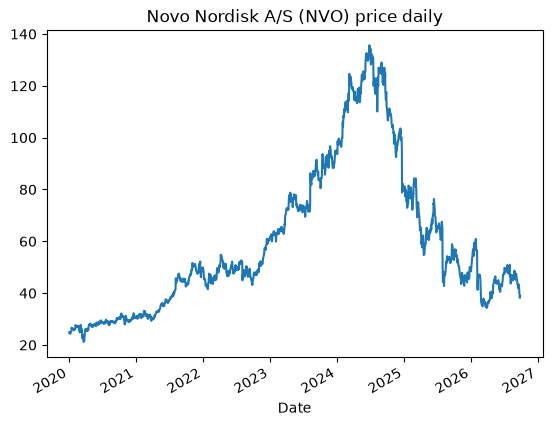

In [38]:
# Chaining: select one column, draw a plot, of a type line
nvo_df_filtered_from_2020['Close'].plot.line(title='Novo Nordisk A/S (NVO) price daily')

In [39]:
# generating new fields (using DateTime features):

nvo_df['Ticker'] = 'NVO'
nvo_df['Year']= nvo_df.index.year
nvo_df['Month'] = nvo_df.index.month
nvo_df['Weekday'] = nvo_df.index.weekday
nvo_df['Date'] = nvo_df.index.date # to be used in joins

In [40]:
nvo_df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,Weekday,Date
Date,,,,,,,,,,,,
2026-09-21 00:00:00-04:00,41.049999,41.169998,39.540001,39.799999,49339300,0.0,0.0,NVO,2026,9,0,2026-09-21
2026-09-22 00:00:00-04:00,39.500000,39.889999,39.110001,39.400002,24462900,0.0,0.0,NVO,2026,9,1,2026-09-22
2026-09-23 00:00:00-04:00,38.900002,39.139999,38.160000,38.169998,18439000,0.0,0.0,NVO,2026,9,2,2026-09-23
2026-09-24 00:00:00-04:00,37.950001,38.720001,37.919998,38.619999,20064200,0.0,0.0,NVO,2026,9,3,2026-09-24
2026-09-25 00:00:00-04:00,38.810001,38.830002,38.410000,38.799999,9922900,0.0,0.0,NVO,2026,9,4,2026-09-25


In [41]:
# shift ALL values (on x periods forward (+1) and backward (-1))
# equivalent of joining with a dataframe of the same vector, but with shifted date index
nvo_df['close_minus_1'] = nvo_df['Close'].shift(-1)
nvo_df['close_plus_1'] = nvo_df['Close'].shift(1)

nvo_df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,Weekday,Date,close_minus_1,close_plus_1
Date,,,,,,,,,,,,,,
2026-09-21 00:00:00-04:00,41.049999,41.169998,39.540001,39.799999,49339300,0.0,0.0,NVO,2026,9,0,2026-09-21,39.400002,43.240002
2026-09-22 00:00:00-04:00,39.500000,39.889999,39.110001,39.400002,24462900,0.0,0.0,NVO,2026,9,1,2026-09-22,38.169998,39.799999
2026-09-23 00:00:00-04:00,38.900002,39.139999,38.160000,38.169998,18439000,0.0,0.0,NVO,2026,9,2,2026-09-23,38.619999,39.400002
2026-09-24 00:00:00-04:00,37.950001,38.720001,37.919998,38.619999,20064200,0.0,0.0,NVO,2026,9,3,2026-09-24,38.799999,38.169998
2026-09-25 00:00:00-04:00,38.810001,38.830002,38.410000,38.799999,9922900,0.0,0.0,NVO,2026,9,4,2026-09-25,NaN,38.619999


In [42]:
# historical growth
nvo_df['growth_1d'] = nvo_df['Close'] / nvo_df['Close'].shift(1)           # nvo_df['close_plus_1']
nvo_df['growth_30d'] = nvo_df['Close'] / nvo_df['Close'].shift(30)

# FUTURE Growth : for regression models
nvo_df['growth_future_1d'] = nvo_df['Close'].shift(-1) / nvo_df['Close']   # nvo_df['close_minus_1']
nvo_df['growth_future_30d'] = nvo_df['Close'].shift(-30) / nvo_df['Close']   # nvo_df['close_minus_1']


# FUTURE Growth: for binary models
nvo_df['is_positive_growth_1d_future'] = np.where(nvo_df['growth_future_1d'] > 1, 1, 0)
nvo_df['is_positive_growth_30d_future'] = np.where(nvo_df['growth_future_30d'] > 1, 1, 0)


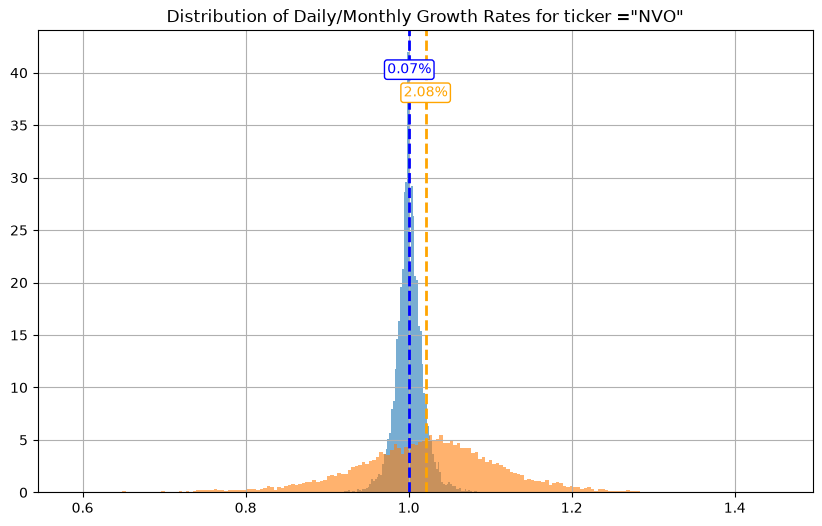

In [43]:
# normally the growth in 1 day is +-10%, while a lot of it is around 0% (around 1.)
plt.figure(figsize=(10, 6))
plt.title('Distribution of Daily/Monthly Growth Rates for ticker ="NVO"')

nvo_df.growth_1d.hist(bins=200, alpha=0.6, density=True)
nvo_df.growth_30d.hist(bins=200, alpha=0.6, density=True)

# Add vertical lines for averages
mean_1d = nvo_df.growth_1d.mean()
mean_30d = nvo_df.growth_30d.mean()

plt.axvline(mean_1d, color='blue', linestyle='--', linewidth=2, label=f'1d avg = {mean_1d:.3f}')
plt.axvline(mean_30d, color='orange', linestyle='--', linewidth=2, label=f'30d avg = {mean_30d:.3f}')


# Add mean text labels (as percent change)
ymax = plt.ylim()[1]
plt.text(mean_1d, ymax * 0.90,
         f'{(mean_1d - 1) * 100:.2f}%',
         color='blue', ha='center', va='bottom',
         bbox=dict(facecolor='white', edgecolor='blue', boxstyle='round,pad=0.2'))

plt.text(mean_30d, ymax * 0.85,
         f'{(mean_30d - 1) * 100:.2f}%',
         color='orange', ha='center', va='bottom',
         bbox=dict(facecolor='white', edgecolor='orange', boxstyle='round,pad=0.2'))


plt.show()

<Axes: title={'center': 'Distribution of 30-days Growth Rates for ticker = "NVO"'}>

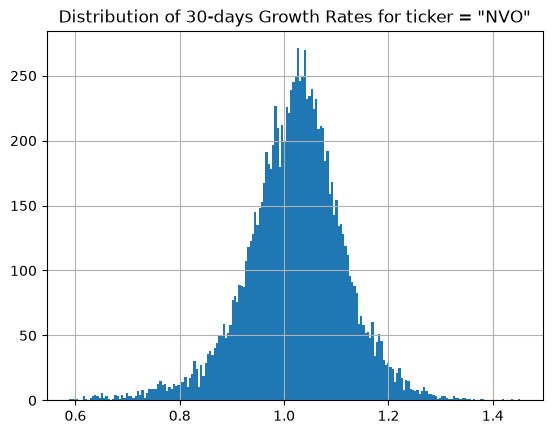

In [44]:
# you can see that the growth is can be much wider in 30 days (+- 30%)
plt.title('Distribution of 30-days Growth Rates for ticker = "NVO"')

nvo_df.growth_30d.hist(bins=200)

In [45]:
# for modeling: we use growth_1d, growth_2d as feature
COLUMNS = [k for k in nvo_df.keys() if k.find('growth')>=0 or k=='Close']
nvo_df[COLUMNS].tail()  


,Close,growth_1d,growth_30d,growth_future_1d,growth_future_30d,is_positive_growth_1d_future,is_positive_growth_30d_future
Date,,,,,,,
2026-09-21 00:00:00-04:00,39.799999,0.920444,0.852911,0.989950,NaN,0,0
2026-09-22 00:00:00-04:00,39.400002,0.989950,0.836025,0.968782,NaN,0,0
2026-09-23 00:00:00-04:00,38.169998,0.968782,0.819541,1.011789,NaN,1,0
2026-09-24 00:00:00-04:00,38.619999,1.011789,0.843145,1.004661,NaN,1,0
2026-09-25 00:00:00-04:00,38.799999,1.004661,0.841092,NaN,NaN,0,0


In [46]:
# Calculate the distribution if future growth
nvo_df.dropna(subset=['growth_future_1d']).is_positive_growth_1d_future.value_counts() / len(nvo_df.dropna(subset=['growth_future_1d']))

is_positive_growth_1d_future
0    0.513065
1    0.486935
Name: count, dtype: float64

In [47]:
nvo_df.dropna(subset=['growth_future_30d']).is_positive_growth_30d_future.value_counts() / len(nvo_df.dropna(subset=['growth_future_30d']))

is_positive_growth_30d_future
1    0.617663
0    0.382337
Name: count, dtype: float64

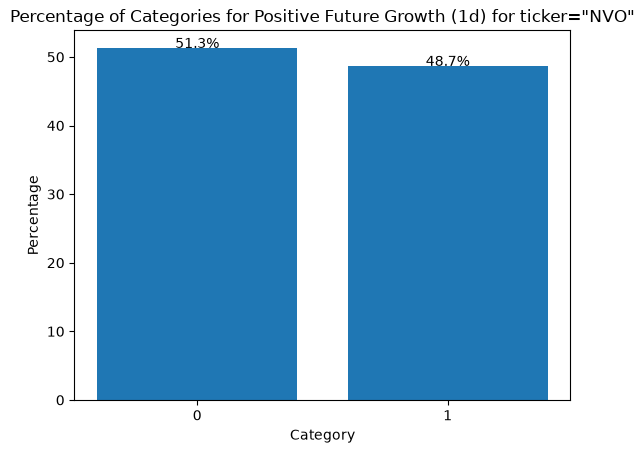

In [48]:
# Calculate value counts
value_counts = nvo_df.dropna(subset=['growth_future_1d'])['is_positive_growth_1d_future'].value_counts()

# Calculate percentage of each category
percentage = (value_counts / len(nvo_df.dropna(subset=['growth_future_1d']))) * 100

# # Plot as a bar chart
plt.bar(percentage.index.astype(str), percentage)
plt.xlabel('Category')
plt.ylabel('Percentage')
plt.title('Percentage of Categories for Positive Future Growth (1d) for ticker="NVO"')

# Add percentage values on top of each bar
for i, value in enumerate(percentage):
    plt.text(i, value + 0, f'{value:.1f}%', ha='center')

plt.show()

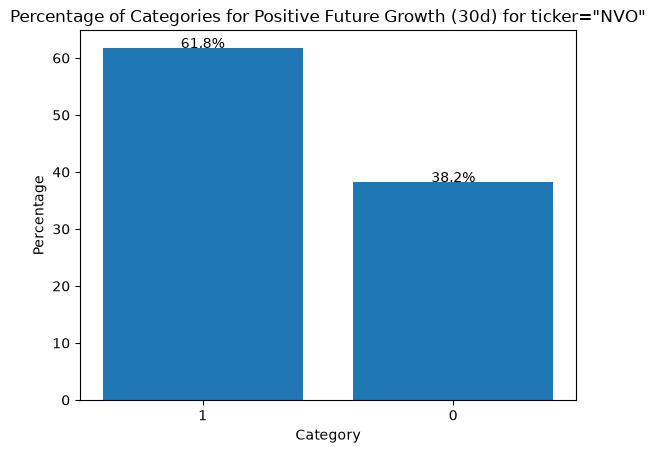

In [49]:
# Calculate value counts
value_counts = nvo_df.dropna(subset=['growth_future_30d'])['is_positive_growth_30d_future'].value_counts()

# Calculate percentage of each category
percentage = (value_counts / len(nvo_df.dropna(subset=['growth_future_30d']))) * 100

# # Plot as a bar chart
plt.bar(percentage.index.astype(str), percentage)
plt.xlabel('Category')
plt.ylabel('Percentage')
plt.title('Percentage of Categories for Positive Future Growth (30d) for ticker="NVO"')

# Add percentage values on top of each bar
for i, value in enumerate(percentage):
    plt.text(i, value + 0, f'{value:.1f}%', ha='center')

plt.show()

2.2 [Code Snippet 6] Candlestick chart for OHLCV

In [50]:
# Candlestick charts : https://plotly.com/python/candlestick-charts/
import plotly.graph_objects as go

fig = go.Figure(data=[go.Candlestick(x=nvo_df_filtered_from_2020.index,
                open=nvo_df_filtered_from_2020.Open,
                high=nvo_df_filtered_from_2020.High,
                low=nvo_df_filtered_from_2020.Low,
                close=nvo_df_filtered_from_2020.Close)
               ])

fig.update_layout(
    title="NVO's daily candlestick chart from 2020",
    title_x=0.5,  # Set title x-position to center
    xaxis_rangeslider_visible=True
    )

fig.show()

3) Macro Indicators

3.0 Previous indicators from module 1

In [51]:
end = date.today()
print(f'Year = {end.year}; month= {end.month}; day={end.day}')

start = date(year=end.year-70, month=end.month, day=end.day)
print(f'Period for indexes: {start} to {end} ')

Year = 2026; month= 9; day=27
Period for indexes: 1956-09-27 to 2026-09-27 


In [52]:
# reuse code for ealier covered indicators
ticker_obj = yf.Ticker("^GDAXI")
dax_daily = ticker_obj.history(period = "max", interval = "1d")

In [53]:
for i in [1,3,7,30,90,365]:
  #DEBUG: dax_daily['Adj Close_sh_m_'+str(i)+'d'] = dax_daily['Adj Close'].shift(i)
  dax_daily['growth_dax_'+str(i)+'d'] = dax_daily['Close'] / dax_daily['Close'].shift(i)

In [54]:
dax_daily.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,,,,,,,,
1987-12-30 00:00:00+01:00,1005.190002,1005.190002,1005.190002,1005.190002,0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1988-01-04 00:00:00+01:00,956.489990,956.489990,956.489990,956.489990,0,0.0,0.0,0.951551,NaN,NaN,NaN,NaN,NaN
1988-01-05 00:00:00+01:00,996.099976,996.099976,996.099976,996.099976,0,0.0,0.0,1.041412,NaN,NaN,NaN,NaN,NaN
1988-01-06 00:00:00+01:00,1006.010010,1006.010010,1006.010010,1006.010010,0,0.0,0.0,1.009949,1.000816,NaN,NaN,NaN,NaN
1988-01-07 00:00:00+01:00,1014.469971,1014.469971,1014.469971,1014.469971,0,0.0,0.0,1.008409,1.060617,NaN,NaN,NaN,NaN


In [55]:
dax_daily.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,,,,,,,,
2026-09-24 00:00:00+02:00,25263.109375,25424.210938,25164.199219,25266.529297,53978600,0.0,0.0,0.994329,0.987938,0.994656,0.960714,1.026812,1.185609
2026-09-25 00:00:00+02:00,25441.789062,25529.330078,25347.300781,25408.640625,52413000,0.0,0.0,1.005624,0.993346,0.994944,0.960981,1.020896,1.198190


In [56]:
GROWTH_KEYS = [k for k in dax_daily.keys() if k.startswith('growth')]
dax_daily_to_merge = dax_daily[GROWTH_KEYS]
dax_daily_to_merge.tail(1)

,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,
2026-09-25 00:00:00+02:00,1.005624,0.993346,0.994944,0.960981,1.020896,1.19819


In [57]:
def get_growth_df(df:pd.DataFrame, prefix:str)->pd.DataFrame:
  for i in [1,3,7,30,90,365]:
    df['growth_'+prefix+'_'+str(i)+'d'] = df['Close'] / df['Close'].shift(i)
    GROWTH_KEYS = [k for k in df.keys() if k.startswith('growth')]
  return df[GROWTH_KEYS]

In [58]:
# https://finance.yahoo.com/quote/%5EGSPC/
# SNP - SNP Real Time Price. Currency in USD
ticker_obj = yf.Ticker("^GSPC")

# snp500_daily = yf.download(tickers = "^GSPC",
#                      period = "max",
#                      interval = "1d")

snp500_daily = ticker_obj.history(
                     period = "max",
                     interval = "1d")

In [59]:
snp500_to_merge = get_growth_df(snp500_daily,'snp500')
snp500_to_merge.tail(2)

,growth_snp500_1d,growth_snp500_3d,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d
Date,,,,,,
2026-09-24 00:00:00-04:00,0.999753,0.992199,1.015608,0.994274,1.039904,1.462425
2026-09-25 00:00:00-04:00,1.005099,0.997266,1.025371,0.992873,1.045976,1.443761


In [60]:
# Dow Jones Industrial Average: https://finance.yahoo.com/quote/%5EDJI?.tsrc=fin-srch

ticker_obj = yf.Ticker("^DJI")

# dji_daily = yf.download(tickers = "^DJI",
#                      period = "max",
#                      interval = "1d")


dji_daily = ticker_obj.history(
                     period = "max",
                     interval = "1d")

In [61]:
dji_daily_to_merge = get_growth_df(dji_daily,'dji')
dji_daily_to_merge.tail(2)

,growth_dji_1d,growth_dji_3d,growth_dji_7d,growth_dji_30d,growth_dji_90d,growth_dji_365d
Date,,,,,,
2026-09-24 00:00:00-04:00,0.996863,0.986573,0.985735,0.954988,1.036825,1.296924
2026-09-25 00:00:00-04:00,1.009321,0.999324,1.007126,0.962642,1.043121,1.288862


In [62]:
# ETFs
# WisdomTree India Earnings Fund (EPI)
# NYSEArca - Nasdaq Real Time Price. Currency in USD
# WEB: https://finance.yahoo.com/quote/EPI/history?p=EPI

# epi_etf_daily = yf.download(tickers = "EPI",
#                      period = "max",
#                      interval = "1d")

ticker_obj = yf.Ticker("EPI")
epi_etf_daily = ticker_obj.history(
                     period = "max",
                     interval = "1d")

epi_etf_daily.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Capital Gains
Date,,,,,,,,
2026-09-24 00:00:00-04:00,41.619999,41.700001,41.450001,41.509998,384100,0.0,0.0,0.0
2026-09-25 00:00:00-04:00,41.680000,41.830002,41.580002,41.799999,335300,0.0,0.0,0.0


In [63]:
epi_etf_daily_to_merge = get_growth_df(epi_etf_daily,'epi')
epi_etf_daily_to_merge.tail(2)

,growth_epi_1d,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d
Date,,,,,,
2026-09-24 00:00:00-04:00,0.993775,0.986689,1.003384,0.959325,0.986220,0.976246
2026-09-25 00:00:00-04:00,1.006986,0.995949,1.011127,0.966251,0.999522,0.978235


In [64]:
# Real Potential Gross Domestic Product (GDPPOT), Billions of Chained 2012 Dollars, QUARTERLY
# https://fred.stlouisfed.org/series/GDPPOT
gdppot = pdr.DataReader("GDPPOT", "fred", start=start)
gdppot['gdppot_us_yoy'] = gdppot.GDPPOT/gdppot.GDPPOT.shift(4)-1
gdppot['gdppot_us_qoq'] = gdppot.GDPPOT/gdppot.GDPPOT.shift(1)-1
gdppot.tail(2)

,GDPPOT,gdppot_us_yoy,gdppot_us_qoq
DATE,,,
2026-04-01,24070.938648,0.022185,0.005254
2026-07-01,24200.444694,0.021972,0.005380


In [65]:
gdppot_to_merge = gdppot[['gdppot_us_yoy','gdppot_us_qoq']]
gdppot_to_merge.tail(1)

,gdppot_us_yoy,gdppot_us_qoq
DATE,,
2026-07-01,0.021972,0.00538


In [66]:
# # "Core CPI index", MONTHLY
# https://fred.stlouisfed.org/series/CPILFESL
# The "Consumer Price Index for All Urban Consumers: All Items Less Food & Energy"
# is an aggregate of prices paid by urban consumers for a typical basket of goods, excluding food and energy.
# This measurement, known as "Core CPI," is widely used by economists because food and energy have very volatile prices.
cpilfesl = pdr.DataReader("CPILFESL", "fred", start=start)
cpilfesl['cpi_core_yoy'] = cpilfesl.CPILFESL/cpilfesl.CPILFESL.shift(12)-1
cpilfesl['cpi_core_mom'] = cpilfesl.CPILFESL/cpilfesl.CPILFESL.shift(1)-1

cpilfesl.tail(2)

,CPILFESL,cpi_core_yoy,cpi_core_mom
DATE,,,
2026-07-01,336.789,0.024665,0.002154
2026-08-01,337.765,0.024462,0.002898


In [67]:
cpilfesl_to_merge = cpilfesl[['cpi_core_yoy','cpi_core_mom']]
cpilfesl_to_merge.tail(2)

,cpi_core_yoy,cpi_core_mom
DATE,,
2026-07-01,0.024665,0.002154
2026-08-01,0.024462,0.002898


In [68]:
# Fed rate https://fred.stlouisfed.org/series/FEDFUNDS
fedfunds = pdr.DataReader("FEDFUNDS", "fred", start=start)
fedfunds.tail(2)

,FEDFUNDS
DATE,
2026-07-01,3.63
2026-08-01,3.63


In [69]:
# https://fred.stlouisfed.org/series/DGS1
dgs1 = pdr.DataReader("DGS1", "fred", start=start)
dgs1.tail(2)

,DGS1
DATE,
2026-09-23,4.49
2026-09-24,4.51


In [70]:
# https://fred.stlouisfed.org/series/DGS5
dgs5 = pdr.DataReader("DGS5", "fred", start=start)
dgs5.tail(2)

,DGS5
DATE,
2026-09-23,4.99
2026-09-24,5.03


In [71]:
# https://fred.stlouisfed.org/series/DGS10
dgs10 = pdr.DataReader("DGS10", "fred", start=start)
dgs10.tail(2)

,DGS10
DATE,
2026-09-23,5.11
2026-09-24,5.18


3.1 [Code snippet 3] VIX - Volatility Index

In [72]:
# VIX - Volatility Index
# https://finance.yahoo.com/quote/%5EVIX/

ticker_obj = yf.Ticker("^VIX")

# vix = yf.download(tickers = "^VIX",
#                      period = "max",
#                      interval = "1d")

vix = ticker_obj.history(
                     period = "max",
                     interval = "1d")

In [73]:
vix.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-24 00:00:00-05:00,15.83,16.57,15.34,15.67,0,0.0,0.0
2026-09-25 00:00:00-05:00,15.61,15.94,14.68,14.87,0,0.0,0.0


In [74]:
vix_to_merge = vix['Close']
vix_to_merge.tail()

Date
2026-09-21 00:00:00-05:00    14.87
2026-09-22 00:00:00-05:00    14.21
2026-09-23 00:00:00-05:00    15.18
2026-09-24 00:00:00-05:00    15.67
2026-09-25 00:00:00-05:00    14.87
Name: Close, dtype: float64

<Axes: title={'center': 'VIX value over time'}, xlabel='Date'>

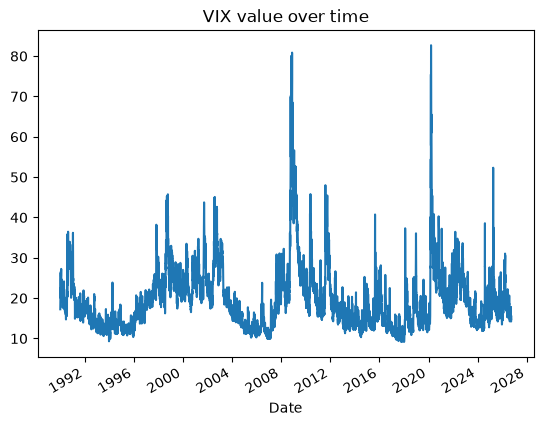

In [75]:
# Static graphs: hard to zoom in and get the exact dates of spikes
vix['Close'].plot.line(title = "VIX value over time")   


In [76]:
# Dynamic visualisation of VIX prices
fig = px.line(vix,
              x=vix.index,
              y="Close",
              title='VIX over time')
fig.update_layout(title_x=0.5)  # This will center the title horizontally

fig.show()

3.2) Gold - other assets

In [77]:
# GOLD
# WEB: https://finance.yahoo.com/quote/GC%3DF

ticker_obj = yf.Ticker("GC=F")

# gold = yf.download(tickers = "GC=F",
#                      period = "max",
#                      interval = "1d")

gold = ticker_obj.history(
                     period = "max",
                     interval = "1d")

In [78]:
gold.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-25 00:00:00-04:00,4309.5,4351.600098,4289.200195,4321.200195,137070,0.0,0.0


In [79]:
gold_to_merge = get_growth_df(gold,'gold')
gold_to_merge.tail(2)

,growth_gold_1d,growth_gold_3d,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d
Date,,,,,,
2026-09-24 00:00:00-04:00,0.995276,0.980406,0.991968,0.962059,0.942151,1.324662
2026-09-25 00:00:00-04:00,1.005398,0.987387,0.984889,0.977559,0.948047,1.339367


In [80]:
# Dynamic visualisation of GOLD prices
fig = px.line(gold,
              x=gold.index,
              y="Close",
              title='GOLD over time')
fig.update_layout(title_x=0.5)  # This will center the title horizontally

fig.show()

3.3) WTI Crude and Brent Oil

In [81]:
# WTI Crude Oil
# WEB: https://uk.finance.yahoo.com/quote/CL=F/

ticker_obj = yf.Ticker("CL=F")

# crude_oil = yf.download(tickers = "CL=F",
#                      period = "max",
#                      interval = "1d")

crude_oil = ticker_obj.history(
                     period = "max",
                     interval = "1d")

In [82]:
crude_oil.tail(2)  


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-24 00:00:00-04:00,92.720001,96.779999,91.230003,94.610001,410015,0.0,0.0
2026-09-25 00:00:00-04:00,94.750000,94.750000,91.510002,92.410004,323945,0.0,0.0


In [83]:
crude_oil_to_merge = get_growth_df(crude_oil,'wti_oil')
crude_oil_to_merge.tail(2)

,growth_wti_oil_1d,growth_wti_oil_3d,growth_wti_oil_7d,growth_wti_oil_30d,growth_wti_oil_90d,growth_wti_oil_365d
Date,,,,,,
2026-09-24 00:00:00-04:00,1.026584,0.987785,0.893981,1.136184,0.897458,1.538374
2026-09-25 00:00:00-04:00,0.976747,0.976953,0.902177,1.137354,0.850451,1.501869


In [84]:
# Dynamic visualisation
fig = px.line(crude_oil,
              x=crude_oil.index,
              y="Close",
              title='WTI Crude Oil over time')
fig.update_layout(title_x=0.5)  # This will center the title horizontally

fig.show()

In [85]:
# Brent Oil
# WEB: https://uk.finance.yahoo.com/quote/BZ=F/

ticker_obj = yf.Ticker("BZ=F")

# brent_oil = yf.download(tickers = "BZ=F",
#                      period = "max",
#                      interval = "1d")

brent_oil = ticker_obj.history(
                     period = "max",
                     interval = "1d")

brent_oil.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-24 00:00:00-04:00,103.389999,108.230003,101.839996,106.599998,57116,0.0,0.0
2026-09-25 00:00:00-04:00,106.519997,100.260002,96.389999,97.440002,63901,0.0,0.0


In [86]:
brent_oil_to_merge = get_growth_df(brent_oil,'brent_oil')
brent_oil_to_merge.tail(2)

,growth_brent_oil_1d,growth_brent_oil_3d,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d
Date,,,,,,
2026-09-24 00:00:00-04:00,1.034148,1.062388,0.980230,1.198022,0.975654,1.646078
2026-09-25 00:00:00-04:00,0.914071,0.981763,0.920722,1.119100,0.869224,1.501850


In [87]:
# Dynamic visualisation
fig = px.line(brent_oil,
              x=brent_oil.index,
              y="Close",
              title='Brent Oil over time')
fig.update_layout(title_x=0.5)  # This will center the title horizontally

fig.show()

3.4) Bitcoin prices: BTC_USD

In [88]:
# https://finance.yahoo.com/quote/BTC-USD/

ticker_obj = yf.Ticker("BTC-USD")

# btc_usd =  yf.download(tickers = "BTC-USD",
#                      period = "max",
#                      interval = "1d")


btc_usd =  ticker_obj.history(
                     period = "max",
                     interval = "1d")

btc_usd.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-09-26 00:00:00+00:00,84035.820312,84423.179688,83781.109375,84406.453125,15169336375,0.0,0.0
2026-09-27 00:00:00+00:00,84429.015625,85021.703125,84245.750000,84476.203125,18734319616,0.0,0.0


In [89]:
btc_usd_to_merge = get_growth_df(btc_usd,'btc_usd')
btc_usd_to_merge.tail(2)

,growth_btc_usd_1d,growth_btc_usd_3d,growth_btc_usd_7d,growth_btc_usd_30d,growth_btc_usd_90d,growth_btc_usd_365d
Date,,,,,,
2026-09-26 00:00:00+00:00,1.004421,1.000278,1.039057,1.051695,1.417825,0.769340
2026-09-27 00:00:00+00:00,1.000826,1.001151,1.041083,1.085390,1.404697,0.770192


In [90]:
# Dynamic visualisation
fig = px.line(btc_usd,
              x=btc_usd.index,
              y="Close",
              title='Bitcoin price daily')
fig.update_layout(title_x=0.5)  # This will center the title horizontally

fig.show()

3.5 [Code snippet 4] Eurostat: "The home of high-quality statistics and data on Europe"

In [91]:
import eurostat

In [92]:
# LONG WAIT TIME ~15 min, unless you filter data

# https://ec.europa.eu/eurostat/cache/metadata/en/irt_euryld_esms.htm
  # Euro yield curves (irt_euryld)
  # Reference Metadata in Euro SDMX Metadata Structure (ESMS)
  # Compiling agency: Eurostat, the statistical office of the European Uni

# the service is slow, you need to specify addtional params : https://pypi.org/project/eurostat/0.2.3/

filter_pars = {'startPeriod':'2026-08-31', 'endPeriod':'2026-09-06'}

code = 'irt_euryld_d'
eurostat_euro_yield_df = eurostat.get_data_df(code, flags=True, filter_pars=filter_pars,  verbose=True)

Download progress: 100.0%



In [93]:
eurostat_euro_yield_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2148 entries, 0 to 2147
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   freq              2148 non-null   str    
 1   yld_curv          2148 non-null   str    
 2   maturity          2148 non-null   str    
 3   bonds             2148 non-null   str    
 4   geo\TIME_PERIOD   2148 non-null   str    
 5   2026-08-31_value  2148 non-null   float64
 6   2026-08-31_flag   2148 non-null   str    
 7   2026-09-01_value  2148 non-null   float64
 8   2026-09-01_flag   2148 non-null   str    
 9   2026-09-02_value  2148 non-null   float64
 10  2026-09-02_flag   2148 non-null   str    
 11  2026-09-03_value  2148 non-null   float64
 12  2026-09-03_flag   2148 non-null   str    
 13  2026-09-04_value  2148 non-null   float64
 14  2026-09-04_flag   2148 non-null   str    
dtypes: float64(5), str(10)
memory usage: 298.4 KB


In [94]:
eurostat_euro_yield_df.head()

,freq,yld_curv,maturity,bonds,geo\TIME_PERIOD,2026-08-31_value,2026-08-31_flag,2026-09-01_value,2026-09-01_flag,2026-09-02_value,2026-09-02_flag,2026-09-03_value,2026-09-03_flag,2026-09-04_value,2026-09-04_flag
0,D,INS_FWD,M10,CGB_EA,EA,2.99586,,3.01466,,3.06000,,3.01606,,2.99200,
1,D,INS_FWD,M10,CGB_EA_AAA,EA,2.91537,,2.93919,,2.98761,,2.96601,,2.94878,
2,D,INS_FWD,M11,CGB_EA,EA,3.01626,,3.03579,,3.08304,,3.03717,,3.01120,
3,D,INS_FWD,M11,CGB_EA_AAA,EA,2.93753,,2.96217,,3.01071,,2.98697,,2.96960,
4,D,INS_FWD,M3,CGB_EA,EA,2.65833,,2.66916,,2.69979,,2.69313,,2.69038,


In [95]:
eurostat_euro_yield_df['bonds'].value_counts()

bonds
CGB_EA        1074
CGB_EA_AAA    1074
Name: count, dtype: int64

In [96]:
eurostat_euro_yield_df['maturity'].value_counts()

maturity
M10      6
M11      6
M3       6
M4       6
M5       6
        ..
Y9_M5    6
Y9_M6    6
Y9_M7    6
Y9_M8    6
Y9_M9    6
Name: count, Length: 358, dtype: int64

In [97]:
eurostat_euro_yield_df['yld_curv'].value_counts()

yld_curv
INS_FWD    716
PAR        716
SPOT_RT    716
Name: count, dtype: int64

In [98]:
eurostat_euro_yield_df

,freq,yld_curv,maturity,bonds,geo\TIME_PERIOD,2026-08-31_value,2026-08-31_flag,2026-09-01_value,2026-09-01_flag,2026-09-02_value,2026-09-02_flag,2026-09-03_value,2026-09-03_flag,2026-09-04_value,2026-09-04_flag
0,D,INS_FWD,M10,CGB_EA,EA,2.99586,,3.01466,,3.06000,,3.01606,,2.99200,
1,D,INS_FWD,M10,CGB_EA_AAA,EA,2.91537,,2.93919,,2.98761,,2.96601,,2.94878,
2,D,INS_FWD,M11,CGB_EA,EA,3.01626,,3.03579,,3.08304,,3.03717,,3.01120,
3,D,INS_FWD,M11,CGB_EA_AAA,EA,2.93753,,2.96217,,3.01071,,2.98697,,2.96960,
4,D,INS_FWD,M3,CGB_EA,EA,2.65833,,2.66916,,2.69979,,2.69313,,2.69038,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2143,D,SPOT_RT,Y9_M7,CGB_EA_AAA,EA,3.31259,,3.32831,,3.36502,,3.33722,,3.31958,
2144,D,SPOT_RT,Y9_M8,CGB_EA,EA,3.74107,,3.75831,,3.79659,,3.76034,,3.73914,
2145,D,SPOT_RT,Y9_M8,CGB_EA_AAA,EA,3.31804,,3.33373,,3.37044,,3.34276,,3.32502,
2146,D,SPOT_RT,Y9_M9,CGB_EA,EA,3.74834,,3.76556,,3.80375,,3.76752,,3.74633,


In [99]:
# Visual graph: https://www.ecb.europa.eu/stats/financial_markets_and_interest_rates/euro_area_yield_curves/html/index.en.html
FILTER = (eurostat_euro_yield_df.yld_curv=='SPOT_RT')& (eurostat_euro_yield_df.bonds=='CGB_EA_AAA')
filtered_eurostat_euro_yield_df = eurostat_euro_yield_df[FILTER]

In [100]:
filtered_eurostat_euro_yield_df.sort_values(by='maturity')[['maturity','2026-09-01_value']].head(20)

,maturity,2026-09-01_value
1433,M10,2.68217
1435,M11,2.70662
1437,M3,2.42149
1439,M4,2.47067
1441,M5,2.51524
1443,M6,2.55561
1445,M7,2.59215
1447,M8,2.62522
1449,M9,2.65513
1451,Y1,2.72871


In [101]:
filtered_eurostat_euro_yield_df.sort_values(by='maturity')[['maturity','2026-09-01_value']].head(20)

,maturity,2026-09-01_value
1433,M10,2.68217
1435,M11,2.70662
1437,M3,2.42149
1439,M4,2.47067
1441,M5,2.51524
1443,M6,2.55561
1445,M7,2.59215
1447,M8,2.62522
1449,M9,2.65513
1451,Y1,2.72871


In [102]:
import re

def extract_numbers(input_string):
    y_match = re.search(r'Y(\d+)', input_string)
    m_match = re.search(r'M(\d+)', input_string)

    y_number = int(y_match.group(1)) if y_match else 0
    m_number = int(m_match.group(1)) if m_match else 0


    return y_number*12 + m_number

# Examples
examples = ["Y10_M2", "M3", "Y1"]
for example in examples:
    res = extract_numbers(example)
    print(f"{example} ==> {res}")

Y10_M2 ==> 122
M3 ==> 3
Y1 ==> 12


In [103]:
# define new field: "maturity in months"
filtered_eurostat_euro_yield_df.loc[:,'maturity_in_months'] = filtered_eurostat_euro_yield_df.maturity.apply(lambda x:extract_numbers(x))

In [104]:
filtered_eurostat_euro_yield_df.sort_values(by='maturity_in_months')[['maturity','maturity_in_months','2026-09-01_value']].head(20)

,maturity,maturity_in_months,2026-09-01_value
1437,M3,3,2.42149
1439,M4,4,2.47067
1441,M5,5,2.51524
1443,M6,6,2.55561
1445,M7,7,2.59215
1447,M8,8,2.62522
1449,M9,9,2.65513
1433,M10,10,2.68217
1435,M11,11,2.70662
1451,Y1,12,2.72871


In [105]:
filtered_eurostat_euro_yield_df.loc[:,'maturity_in_years'] = filtered_eurostat_euro_yield_df.maturity_in_months/12.0

<Axes: title={'center': 'AAA rated bonds spot yield curve'}, xlabel='maturity_in_years'>

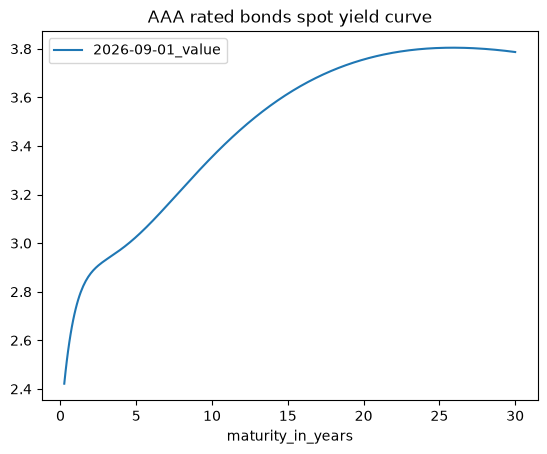

In [106]:
# exactly the same as on the Web:  https://www.ecb.europa.eu/stats/financial_markets_and_interest_rates/euro_area_yield_curves/html/index.en.html
filtered_eurostat_euro_yield_df \
  .sort_values(by='maturity_in_months')[['maturity_in_years','2026-09-01_value']] \
  .plot.line(x='maturity_in_years',
            y='2026-09-01_value',
            title='AAA rated bonds spot yield curve')

4) [Code Snippet 5] Fundamental indicators

In [107]:
# let's select some set of stocks: e.g. top US companies on 'Employees':
# https://companiesmarketcap.com/usa/largest-american-companies-by-number-of-employees/

US_TOP_EMPLOYEES_STOCKS = ['WMT','AMZN','UPS','HD','CNXC','TGT','KR','UNH','BRK-B','SBUX']

# WMT
ticker = US_TOP_EMPLOYEES_STOCKS[0]

# WMT ticker
one_company = yf.Ticker(ticker)

In [108]:
# Fundamental info appears close earning dates, you need to download it and use quickly (before/after trading day),
#  unless you're a fundamental long-term investor looking for a several months-quarters-years strategy (period between buy and sell)
# This dfthis is the easiest thing to join with the main dataset and get "some" technical indicators present
# WMT ticker
eps_earnings = one_company.earnings_dates
eps_earnings['Ticker'] = ticker
eps_earnings

,EPS Estimate,Reported EPS,Surprise(%),Ticker
Earnings Date,,,,
2026-11-19 07:00:00-05:00,0.64,NaN,NaN,WMT
2026-08-20 06:00:00-04:00,0.74,0.81,9.27,WMT
2026-05-21 06:00:00-04:00,0.66,0.66,0.19,WMT
2026-02-19 06:00:00-05:00,0.73,0.74,1.79,WMT
2025-11-20 06:00:00-05:00,0.60,0.62,3.11,WMT
2025-08-21 06:00:00-04:00,0.74,0.68,-7.97,WMT
2025-05-15 06:00:00-04:00,0.58,0.61,5.64,WMT
2025-02-20 06:00:00-05:00,0.65,0.66,2.04,WMT
2024-11-19 06:00:00-05:00,0.53,0.58,8.84,WMT


In [109]:
one_company.calendar

{'Dividend Date': datetime.date(2027, 1, 4),
 'Ex-Dividend Date': datetime.date(2026, 12, 11),
 'Earnings Date': [datetime.date(2026, 11, 19)],
 'Earnings High': 0.67,
 'Earnings Low': 0.62,
 'Earnings Average': 0.63531,
 'Revenue High': 189775000000,
 'Revenue Low': 185556000000,
 'Revenue Average': 187209033440}

In [110]:
one_company.financials

,2026-01-31,2025-01-31,2024-01-31,2023-01-31,2022-01-31
Tax Effect Of Unusual Items,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN
Tax Rate For Calcs,2.442910e-01,2.338360e-01,2.550000e-01,3.360000e-01,NaN
Normalized EBITDA,4.647100e+10,4.201000e+10,3.638400e+10,3.008900e+10,NaN
Total Unusual Items,NaN,NaN,0.000000e+00,0.000000e+00,-2.410000e+09
Total Unusual Items Excluding Goodwill,NaN,NaN,0.000000e+00,0.000000e+00,-2.410000e+09
Net Income From Continuing Operation Net Minority Interest,2.189300e+10,1.943600e+10,1.551100e+10,1.168000e+10,NaN
Reconciled Depreciation,1.420300e+10,1.297300e+10,1.185300e+10,1.094500e+10,NaN
Reconciled Cost Of Revenue,5.353950e+11,5.117530e+11,4.901420e+11,4.637210e+11,NaN
EBITDA,4.647100e+10,4.201000e+10,3.638400e+10,3.008900e+10,NaN
EBIT,3.226800e+10,2.903700e+10,2.453100e+10,1.914400e+10,NaN


In [111]:
EPS = one_company.financials.loc['Basic EPS']
EPS

2026-01-31    2.74
2025-01-31    2.42
2024-01-31    1.92
2023-01-31    1.43
2022-01-31     NaN
Name: Basic EPS, dtype: float64

In [112]:
# or should we use NORMALIZED_EBITDA?
EBITDA = one_company.financials.loc['EBITDA']
EBITDA_margin = one_company.financials.loc['EBITDA'] /  one_company.financials.loc['Total Revenue']

In [113]:
EBITDA_margin

2026-01-31    0.065162
2025-01-31    0.061690
2024-01-31    0.056137
2023-01-31    0.049222
2022-01-31         NaN
dtype: float64

In [114]:
NET_INCOME = one_company.financials.loc['Net Income']
NET_INCOME_margin = one_company.financials.loc['Net Income'] /  one_company.financials.loc['Total Revenue']

In [115]:
NET_INCOME

2026-01-31    2.189300e+10
2025-01-31    1.943600e+10
2024-01-31    1.551100e+10
2023-01-31    1.168000e+10
2022-01-31             NaN
Name: Net Income, dtype: float64

In [116]:
# Compare with Public information - you can fully replicate the numbers (yearly and/or quarterly):
# https://www.wsj.com/market-data/quotes/WMT/financials/annual/income-statement
NET_INCOME_margin

2026-01-31    0.030698
2025-01-31    0.028541
2024-01-31    0.023932
2023-01-31    0.019107
2022-01-31         NaN
dtype: float64

In [117]:
# Combine the series into a DataFrame
df_fin_ratios = pd.DataFrame({
    'NET_INCOME_margin': 100.0 * NET_INCOME_margin, #for visualisation -- Margin in %
    'EBITDA_margin': 100.0 *EBITDA_margin, #for visualisation -- Margin in %
    'EPS': EPS
})

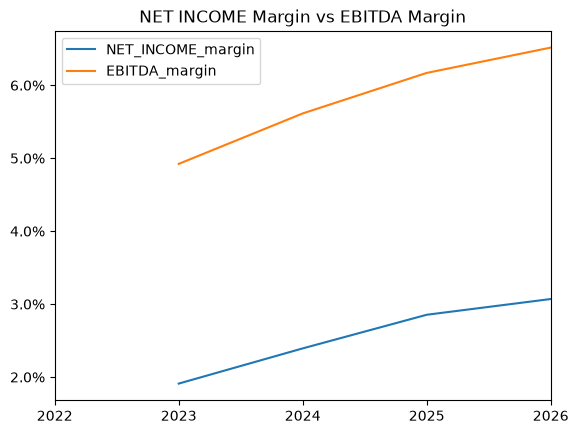

In [118]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Assuming df_fin_ratios is your DataFrame containing the financial ratios
# Make sure you have already created this DataFrame

# Plotting the specified columns
ax = df_fin_ratios[['NET_INCOME_margin','EBITDA_margin']].plot.line()

# Setting the y-axis formatter to display values as percentages
ax.yaxis.set_major_formatter(mtick.PercentFormatter())

# Adding title
plt.title('NET INCOME Margin vs EBITDA Margin')

# Displaying the plot
plt.show()

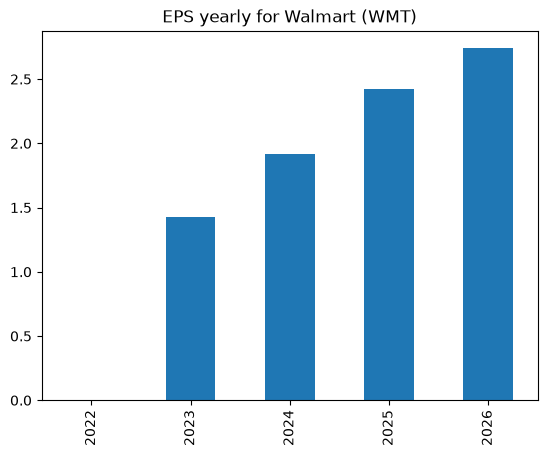

In [119]:
eps_by_year = df_fin_ratios['EPS'].set_axis(df_fin_ratios.index.year).sort_index()

eps_by_year.plot.bar(title='EPS yearly for Walmart (WMT)')
plt.show()


5) [Code snippet 7] Daily OHCLV data for a set of stocks

In [120]:
# https://companiesmarketcap.com/usa/largest-companies-in-the-usa-by-market-cap/
US_STOCKS = ['MSFT', 'AAPL', 'GOOG', 'NVDA', 'AMZN', 'META', 'BRK-B', 'LLY', 'AVGO','V', 'JPM']

# You're required to add EU_STOCKS and INDIA_STOCS
# https://companiesmarketcap.com/european-union/largest-companies-in-the-eu-by-market-cap/
EU_STOCKS = ['NVO','MC.PA', 'ASML', 'RMS.PA', 'OR.PA', 'SAP', 'ACN', 'TTE', 'SIE.DE','IDEXY','CDI.PA']

# https://companiesmarketcap.com/india/largest-companies-in-india-by-market-cap/
INDIA_STOCKS = ['RELIANCE.NS','TCS.NS','HDB','BHARTIARTL.NS','IBN','SBIN.NS','LICI.NS','INFY','ITC.NS','HINDUNILVR.NS','LT.NS']

In [121]:
ALL_TICKERS = US_STOCKS  + EU_STOCKS + INDIA_STOCKS
ALL_TICKERS

['MSFT',
 'AAPL',
 'GOOG',
 'NVDA',
 'AMZN',
 'META',
 'BRK-B',
 'LLY',
 'AVGO',
 'V',
 'JPM',
 'NVO',
 'MC.PA',
 'ASML',
 'RMS.PA',
 'OR.PA',
 'SAP',
 'ACN',
 'TTE',
 'SIE.DE',
 'IDEXY',
 'CDI.PA',
 'RELIANCE.NS',
 'TCS.NS',
 'HDB',
 'BHARTIARTL.NS',
 'IBN',
 'SBIN.NS',
 'LICI.NS',
 'INFY',
 'ITC.NS',
 'HINDUNILVR.NS',
 'LT.NS']

In [122]:
import time

stocks_df = pd.DataFrame({'A' : []})

for i,ticker in enumerate(ALL_TICKERS):
  print(i,ticker)

  # Work with stock prices
  ticker_obj = yf.Ticker(ticker)

  # historyPrices = yf.download(tickers = ticker,
  #                    period = "max",
  #                    interval = "1d")
  historyPrices = ticker_obj.history(
                     period = "max",
                     interval = "1d")

  # generate features for historical prices, and what we want to predict
  historyPrices['Ticker'] = ticker
  historyPrices['Year']= historyPrices.index.year
  historyPrices['Month'] = historyPrices.index.month
  historyPrices['Weekday'] = historyPrices.index.weekday
  historyPrices['Date'] = historyPrices.index.date

  # historical returns
  for i in [1,3,7,30,90,365]:
    historyPrices['growth_'+str(i)+'d'] = historyPrices['Close'] / historyPrices['Close'].shift(i)
  historyPrices['growth_future_30d'] = historyPrices['Close'].shift(-30) / historyPrices['Close']

  # Technical indicators
  # SimpleMovingAverage 10 days and 20 days
  historyPrices['SMA10']= historyPrices['Close'].rolling(10).mean()
  historyPrices['SMA20']= historyPrices['Close'].rolling(20).mean()
  historyPrices['growing_moving_average'] = np.where(historyPrices['SMA10'] > historyPrices['SMA20'], 1, 0)
  historyPrices['high_minus_low_relative'] = (historyPrices.High - historyPrices.Low) / historyPrices['Close']

  # 30d rolling volatility : https://ycharts.com/glossary/terms/rolling_vol_30
  #ERROR, fixed in 2025: historyPrices['volatility'] =   historyPrices['Close'].rolling(30).std() * np.sqrt(252)
  # volatility is calculated on std. dev. or Returns and NOT Close price
  historyPrices['volatility'] = historyPrices['growth_1d'].rolling(30).std() * np.sqrt(252)

  # what we want to predict
  historyPrices['is_positive_growth_30d_future'] = np.where(historyPrices['growth_future_30d'] > 1, 1, 0)

  # sleep 1 sec between downloads - not to overload the API server
  time.sleep(1)


  if stocks_df.empty:
    stocks_df = historyPrices
  else:
    stocks_df = pd.concat([stocks_df, historyPrices], ignore_index=True)

0 MSFT
1 AAPL
2 GOOG
3 NVDA
4 AMZN
5 META
6 BRK-B
7 LLY
8 AVGO
9 V
10 JPM
11 NVO
12 MC.PA
13 ASML
14 RMS.PA
15 OR.PA
16 SAP
17 ACN
18 TTE
19 SIE.DE
20 IDEXY
21 CDI.PA
22 RELIANCE.NS
23 TCS.NS
24 HDB
25 BHARTIARTL.NS
26 IBN
27 SBIN.NS
28 LICI.NS
29 INFY
30 ITC.NS
31 HINDUNILVR.NS
32 LT.NS


In [123]:
def get_ticker_type(ticker:str, us_stocks_list, eu_stocks_list, india_stocks_list):
  if ticker in us_stocks_list:
    return 'US'
  elif ticker in eu_stocks_list:
    return 'EU'
  elif ticker in india_stocks_list:
    return 'INDIA'
  else:
    return 'ERROR'

In [124]:
stocks_df['ticker_type'] = stocks_df.Ticker.apply(lambda x:get_ticker_type(x, US_STOCKS, EU_STOCKS, INDIA_STOCKS))

In [125]:
# count of observations between US-EU-INDIA stocks
stocks_df.ticker_type.value_counts()

ticker_type
US       87306
EU       83708
INDIA    69915
Name: count, dtype: int64

In [126]:
# unique tickers
stocks_df.Ticker.nunique()

33

In [127]:
# count of observations by stock
stocks_df.Ticker.value_counts()

Ticker
LLY              13693
JPM              11727
AAPL             11539
NVO              11444
MSFT             10213
CDI.PA            8939
TTE               8791
ASML              7936
SAP               7807
HINDUNILVR.NS     7719
SBIN.NS           7717
RELIANCE.NS       7716
ITC.NS            7716
SIE.DE            7653
BRK-B             7644
AMZN              7387
NVDA              6962
INFY              6929
MC.PA             6869
RMS.PA            6869
OR.PA             6869
IBN               6664
ACN               6334
HDB               6333
LT.NS             6024
BHARTIARTL.NS     6021
TCS.NS            5992
GOOG              5561
V                 4660
AVGO              4311
IDEXY             4197
META              3609
LICI.NS           1084
Name: count, dtype: int64

In [128]:
stocks_df.groupby(['Ticker','ticker_type']).Date.agg(['min','max'])

,,min,max
Ticker,ticker_type,,
AAPL,US,1980-12-12,2026-09-25
ACN,EU,2001-07-19,2026-09-25
AMZN,US,1997-05-15,2026-09-25
ASML,EU,1995-03-15,2026-09-25
AVGO,US,2009-08-06,2026-09-25
BHARTIARTL.NS,INDIA,2002-07-01,2026-09-25
BRK-B,US,1996-05-09,2026-09-25
CDI.PA,EU,1992-01-27,2026-09-25
GOOG,US,2004-08-19,2026-09-25


In [129]:
#  average growth 365days
stocks_df[stocks_df.Year>=2020].groupby(by=['Year','ticker_type']).growth_365d.mean()

Year  ticker_type
2020  EU             1.247263
      INDIA          1.102300
      US             1.484070
2021  EU             1.583642
      INDIA          1.547188
      US             1.797571
2022  EU             1.191194
      INDIA          1.381114
      US             1.182379
2023  EU             1.246429
      INDIA          1.205688
      US             1.203253
2024  EU             1.406815
      INDIA          1.358507
      US             2.159361
2025  EU             1.061778
      INDIA          1.166797
      US             1.583906
2026  EU             1.053718
      INDIA          0.943267
      US             1.375208
Name: growth_365d, dtype: float64

In [130]:
stocks_df['Date'] = pd.to_datetime(stocks_df['Date'])

In [131]:
# filtering only on stats after 2000
stocks_df[stocks_df.Date>='2000-01-01'].info()

<class 'pandas.DataFrame'>
Index: 202462 entries, 3490 to 240928
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype        
---  ------                         --------------   -----        
 0   Open                           202462 non-null  float64      
 1   High                           202462 non-null  float64      
 2   Low                            202462 non-null  float64      
 3   Close                          202462 non-null  float64      
 4   Volume                         202462 non-null  int64        
 5   Dividends                      202462 non-null  float64      
 6   Stock Splits                   202462 non-null  float64      
 7   Ticker                         202462 non-null  str          
 8   Year                           202462 non-null  int32        
 9   Month                          202462 non-null  int32        
 10  Weekday                        202462 non-null  int32        
 11  Date                      

In [132]:
stocks_df[stocks_df.Date=='2025-04-01'].tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_90d,growth_365d,growth_future_30d,SMA10,SMA20,growing_moving_average,high_minus_low_relative,volatility,is_positive_growth_30d_future,ticker_type
212168,383.312960,388.616661,381.914700,384.638885,1453754,0.0,0.0,LICI.NS,2025,4,...,0.904530,1.249597,1.071827,379.364108,370.261026,1,0.017424,0.257048,1,INDIA
219096,17.297070,17.316087,17.068852,17.306580,13574900,0.0,0.0,INFY,2025,4,...,0.842593,1.105543,1.014286,17.527191,17.811038,0,0.014286,0.211017,1,INDIA
226813,383.673534,387.980270,379.741319,380.724365,15206240,0.0,0.0,ITC.NS,2025,4,...,0.938373,1.003170,1.070577,381.571652,380.401344,1,0.021640,0.140684,1,INDIA
234532,2195.721287,2220.652688,2157.813748,2171.275879,2495962,0.0,0.0,HINDUNILVR.NS,2025,4,...,0.937490,0.919659,1.066634,2174.405469,2153.075183,1,0.028941,0.177949,1,INDIA
240556,3414.493704,3435.687209,3365.434886,3372.106934,1935147,0.0,0.0,LT.NS,2025,4,...,0.986594,1.119636,1.047544,3344.531006,3246.175403,1,0.020833,0.215693,1,INDIA


6) [Code Snippet 8] Technical Indicators with TA-lib

    PythonInvest article on Tech. Indicators
    Code for generating 100+ tech. indicators/patterns : https://github.com/realmistic/PythonInvest-basic-fin-analysis/blob/master/colab_notebooks/Part14_Exploring_Tech_Indicators_For_Stocks_and_Crypto.ipynb

Indicator groups: https://github.com/TA-Lib/ta-lib-python/blob/master/README.md

    Overlap Studies (17)
    Momentum Indicators (30+)
    Volume Indicators (3)
    Cycle Indicators (5)
    Price Transform (4)
    Volatility Indicators (3)
    Pattern Recognition (60)

6.1) Momentum indicators

In [133]:
import talib

In [134]:
def talib_get_momentum_indicators_for_one_ticker(df: pd.DataFrame) -> pd.DataFrame:
  # ADX - Average Directional Movement Index
  talib_momentum_adx = talib.ADX(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # ADXR - Average Directional Movement Index Rating
  talib_momentum_adxr = talib.ADXR(df.High.values, df.Low.values, df.Close.values, timeperiod=14 )
  # APO - Absolute Price Oscillator
  talib_momentum_apo = talib.APO(df.Close.values, fastperiod=12, slowperiod=26, matype=0 )
  # AROON - Aroon
  talib_momentum_aroon = talib.AROON(df.High.values, df.Low.values, timeperiod=14 )
  # talib_momentum_aroon[0].size
  # talib_momentum_aroon[1].size
  # AROONOSC - Aroon Oscillator
  talib_momentum_aroonosc = talib.AROONOSC(df.High.values, df.Low.values, timeperiod=14)
  # BOP - Balance of Power
  # https://school.stockcharts.com/doku.php?id=technical_indicators:balance_of_power
     #calculate open prices as shifted closed prices from the prev day
     # open = df.Last.shift(1)
  talib_momentum_bop = talib.BOP(df.Open.values, df.High.values, df.Low.values, df.Close.values)
  # CCI - Commodity Channel Index
  talib_momentum_cci = talib.CCI(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # CMO - Chande Momentum Oscillator
  talib_momentum_cmo = talib.CMO(df.Close.values, timeperiod=14)
  # DX - Directional Movement Index
  talib_momentum_dx = talib.DX(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # MACD - Moving Average Convergence/Divergence
  talib_momentum_macd, talib_momentum_macdsignal, talib_momentum_macdhist = talib.MACD(df.Close.values, fastperiod=12, \
                                                                                       slowperiod=26, signalperiod=9)
  # MACDEXT - MACD with controllable MA type
  talib_momentum_macd_ext, talib_momentum_macdsignal_ext, talib_momentum_macdhist_ext = talib.MACDEXT(df.Close.values, \
                                                                                                    fastperiod=12, \
                                                                                                    fastmatype=0, \
                                                                                                    slowperiod=26, \
                                                                                                    slowmatype=0, \
                                                                                                    signalperiod=9, \
                                                                                                  signalmatype=0)
  # MACDFIX - Moving Average Convergence/Divergence Fix 12/26
  talib_momentum_macd_fix, talib_momentum_macdsignal_fix, talib_momentum_macdhist_fix = talib.MACDFIX(df.Close.values, \
                                                                                                      signalperiod=9)
  # MFI - Money Flow Index
  talib_momentum_mfi = talib.MFI(df.High.values, df.Low.values, df.Close.values, df.Volume.values, timeperiod=14)
  # MINUS_DI - Minus Directional Indicator
  talib_momentum_minus_di = talib.MINUS_DM(df.High.values, df.Low.values, timeperiod=14)
  # MOM - Momentum
  talib_momentum_mom = talib.MOM(df.Close.values, timeperiod=10)
  # PLUS_DI - Plus Directional Indicator
  talib_momentum_plus_di = talib.PLUS_DI(df.High.values, df.Low.values, df.Close.values, timeperiod=14)
  # PLUS_DM - Plus Directional Movement
  talib_momentum_plus_dm = talib.PLUS_DM(df.High.values, df.Low.values, timeperiod=14)
  # PPO - Percentage Price Oscillator
  talib_momentum_ppo = talib.PPO(df.Close.values, fastperiod=12, slowperiod=26, matype=0)
  # ROC - Rate of change : ((price/prevPrice)-1)*100
  talib_momentum_roc = talib.ROC(df.Close.values, timeperiod=10)
  # ROCP - Rate of change Percentage: (price-prevPrice)/prevPrice
  talib_momentum_rocp = talib.ROCP(df.Close.values, timeperiod=10)
  # ROCR - Rate of change ratio: (price/prevPrice)
  talib_momentum_rocr = talib.ROCR(df.Close.values, timeperiod=10)
  # ROCR100 - Rate of change ratio 100 scale: (price/prevPrice)*100
  talib_momentum_rocr100 = talib.ROCR100(df.Close.values, timeperiod=10)
  # RSI - Relative Strength Index
  talib_momentum_rsi = talib.RSI(df.Close.values, timeperiod=14)
  # STOCH - Stochastic
  talib_momentum_slowk, talib_momentum_slowd = talib.STOCH(df.High.values, df.Low.values, df.Close.values, \
                                                           fastk_period=5, slowk_period=3, slowk_matype=0, slowd_period=3, slowd_matype=0)
  # STOCHF - Stochastic Fast
  talib_momentum_fastk, talib_momentum_fastd = talib.STOCHF(df.High.values, df.Low.values, df.Close.values, \
                                                            fastk_period=5, fastd_period=3, fastd_matype=0)
  # STOCHRSI - Stochastic Relative Strength Index
  talib_momentum_fastk_rsi, talib_momentum_fastd_rsi = talib.STOCHRSI(df.Close.values, timeperiod=14, \
                                                                      fastk_period=5, fastd_period=3, fastd_matype=0)
  # TRIX - 1-day Rate-Of-Change (ROC) of a Triple Smooth EMA
  talib_momentum_trix = talib.TRIX(df.Close.values, timeperiod=30)
  # ULTOSC - Ultimate Oscillator
  talib_momentum_ultosc = talib.ULTOSC(df.High.values, df.Low.values, df.Close.values, timeperiod1=7, timeperiod2=14, timeperiod3=28)
  # WILLR - Williams' %R
  talib_momentum_willr = talib.WILLR(df.High.values, df.Low.values, df.Close.values, timeperiod=14)

  momentum_df =   pd.DataFrame(
    {
      # assume here multi-index 
      # 'datetime': df.index.get_level_values(0),
      # 'ticker': df.index.get_level_values(1) ,

      # old way with separate columns
      'Date': df.Date.values,
      'Ticker': df.Ticker,

      'adx': talib_momentum_adx,
      'adxr': talib_momentum_adxr,
      'apo': talib_momentum_apo,
      'aroon_1': talib_momentum_aroon[0] ,
      'aroon_2': talib_momentum_aroon[1],
      'aroonosc': talib_momentum_aroonosc,
      'bop': talib_momentum_bop,
      'cci': talib_momentum_cci,
      'cmo': talib_momentum_cmo,
      'dx': talib_momentum_dx,
      'macd': talib_momentum_macd,
      'macdsignal': talib_momentum_macdsignal,
      'macdhist': talib_momentum_macdhist,
      'macd_ext': talib_momentum_macd_ext,
      'macdsignal_ext': talib_momentum_macdsignal_ext,
      'macdhist_ext': talib_momentum_macdhist_ext,
      'macd_fix': talib_momentum_macd_fix,
      'macdsignal_fix': talib_momentum_macdsignal_fix,
      'macdhist_fix': talib_momentum_macdhist_fix,
      'mfi': talib_momentum_mfi,
      'minus_di': talib_momentum_minus_di,
      'mom': talib_momentum_mom,
      'plus_di': talib_momentum_plus_di,
      'dm': talib_momentum_plus_dm,
      'ppo': talib_momentum_ppo,
      'roc': talib_momentum_roc,
      'rocp': talib_momentum_rocp,
      'rocr': talib_momentum_rocr,
      'rocr100': talib_momentum_rocr100,
      'rsi': talib_momentum_rsi,
      'slowk': talib_momentum_slowk,
      'slowd': talib_momentum_slowd,
      'fastk': talib_momentum_fastk,
      'fastd': talib_momentum_fastd,
      'fastk_rsi': talib_momentum_fastk_rsi,
      'fastd_rsi': talib_momentum_fastd_rsi,
      'trix': talib_momentum_trix,
      'ultosc': talib_momentum_ultosc,
      'willr': talib_momentum_willr,
     }
  )
  return momentum_df

6.2 Volume, Volatility, Cycle, Price indicators

In [135]:
def talib_get_volume_volatility_cycle_price_indicators(df: pd.DataFrame) -> pd.DataFrame:
        # TA-Lib Volume indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/volume_indicators.md
        # AD - Chaikin A/D Line
        talib_ad = talib.AD(
            df.High.values, df.Low.values, df.Close.values, df.Volume.values)
        # ADOSC - Chaikin A/D Oscillator
        talib_adosc = talib.ADOSC(
            df.High.values, df.Low.values, df.Close.values, df.Volume.values, fastperiod=3, slowperiod=10)
        # OBV - On Balance Volume
        talib_obv = talib.OBV(
            df.Close.values, df.Volume.values)

        # TA-Lib Volatility indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/volatility_indicators.md
        # ATR - Average True Range
        talib_atr = talib.ATR(
            df.High.values, df.Low.values, df.Close.values, timeperiod=14)
        # NATR - Normalized Average True Range
        talib_natr = talib.NATR(
            df.High.values, df.Low.values, df.Close.values, timeperiod=14)
        # OBV - On Balance Volume
        talib_obv = talib.OBV(
            df.Close.values, df.Volume.values)

        # TA-Lib Cycle Indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/cycle_indicators.md
        # HT_DCPERIOD - Hilbert Transform - Dominant Cycle Period
        talib_ht_dcperiod = talib.HT_DCPERIOD(df.Close.values)
        # HT_DCPHASE - Hilbert Transform - Dominant Cycle Phase
        talib_ht_dcphase = talib.HT_DCPHASE(df.Close.values)
        # HT_PHASOR - Hilbert Transform - Phasor Components
        talib_ht_phasor_inphase, talib_ht_phasor_quadrature = talib.HT_PHASOR(
            df.Close.values)
        # HT_SINE - Hilbert Transform - SineWave
        talib_ht_sine_sine, talib_ht_sine_leadsine = talib.HT_SINE(
            df.Close.values)
        # HT_TRENDMODE - Hilbert Transform - Trend vs Cycle Mode
        talib_ht_trendmode = talib.HT_TRENDMODE(df.Close.values)

        # TA-Lib Price Transform Functions
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/price_transform.md
        # AVGPRICE - Average Price
        talib_avgprice = talib.AVGPRICE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # MEDPRICE - Median Price
        talib_medprice = talib.MEDPRICE(df.High.values, df.Low.values)
        # TYPPRICE - Typical Price
        talib_typprice = talib.TYPPRICE(
            df.High.values, df.Low.values, df.Close.values)
        # WCLPRICE - Weighted Close Price
        talib_wclprice = talib.WCLPRICE(
            df.High.values, df.Low.values, df.Close.values)

        volume_volatility_cycle_price_df = pd.DataFrame(
            {'Date': df.Date.values,
             'Ticker': df.Ticker,
             # TA-Lib Volume indicators
             'ad': talib_ad,
             'adosc': talib_adosc,
             'obv': talib_obv,
             # TA-Lib Volatility indicators
             'atr': talib_atr,
             'natr': talib_natr,
             'obv': talib_obv,
             # TA-Lib Cycle Indicators
             'ht_dcperiod': talib_ht_dcperiod,
             'ht_dcphase': talib_ht_dcphase,
             'ht_phasor_inphase': talib_ht_phasor_inphase,
             'ht_phasor_quadrature': talib_ht_phasor_quadrature,
             'ht_sine_sine': talib_ht_sine_sine,
             'ht_sine_leadsine': talib_ht_sine_leadsine,
             'ht_trendmod': talib_ht_trendmode,
             # TA-Lib Price Transform Functions
             'avgprice': talib_avgprice,
             'medprice': talib_medprice,
             'typprice': talib_typprice,
             'wclprice': talib_wclprice,
             }
        )

        # Need a proper date type
        volume_volatility_cycle_price_df['Date'] = pd.to_datetime(
            volume_volatility_cycle_price_df['Date'])

        return volume_volatility_cycle_price_df

6.3) Pattern indicators

In [136]:
def talib_get_pattern_recognition_indicators(df: pd.DataFrame) -> pd.DataFrame:
# TA-Lib Pattern Recognition indicators
        # https://github.com/TA-Lib/ta-lib-python/blob/master/docs/func_groups/pattern_recognition.md
        # Nice article about candles (pattern recognition) https://medium.com/analytics-vidhya/recognizing-over-50-candlestick-patterns-with-python-4f02a1822cb5

        # CDL2CROWS - Two Crows
        talib_cdl2crows = talib.CDL2CROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3BLACKCROWS - Three Black Crows
        talib_cdl3blackrows = talib.CDL3BLACKCROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3INSIDE - Three Inside Up/Down
        talib_cdl3inside = talib.CDL3INSIDE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3LINESTRIKE - Three-Line Strike
        talib_cdl3linestrike = talib.CDL3LINESTRIKE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3OUTSIDE - Three Outside Up/Down
        talib_cdl3outside = talib.CDL3OUTSIDE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3STARSINSOUTH - Three Stars In The South
        talib_cdl3starsinsouth = talib.CDL3STARSINSOUTH(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDL3WHITESOLDIERS - Three Advancing White Soldiers
        talib_cdl3whitesoldiers = talib.CDL3WHITESOLDIERS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLABANDONEDBABY - Abandoned Baby
        talib_cdlabandonedbaby = talib.CDLABANDONEDBABY(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLADVANCEBLOCK - Advance Block
        talib_cdladvancedblock = talib.CDLADVANCEBLOCK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLBELTHOLD - Belt-hold
        talib_cdlbelthold = talib.CDLBELTHOLD(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLBREAKAWAY - Breakaway
        talib_cdlbreakaway = talib.CDLBREAKAWAY(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLCLOSINGMARUBOZU - Closing Marubozu
        talib_cdlclosingmarubozu = talib.CDLCLOSINGMARUBOZU(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLCONCEALBABYSWALL - Concealing Baby Swallow
        talib_cdlconcealbabyswall = talib.CDLCONCEALBABYSWALL(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLCOUNTERATTACK - Counterattack
        talib_cdlcounterattack = talib.CDLCOUNTERATTACK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLDARKCLOUDCOVER - Dark Cloud Cover
        talib_cdldarkcloudcover = talib.CDLDARKCLOUDCOVER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLDOJI - Doji
        talib_cdldoji = talib.CDLDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLDOJISTAR - Doji Star
        talib_cdldojistar = talib.CDLDOJISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLDRAGONFLYDOJI - Dragonfly Doji
        talib_cdldragonflydoji = talib.CDLDRAGONFLYDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLENGULFING - Engulfing Pattern
        talib_cdlengulfing = talib.CDLENGULFING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLEVENINGDOJISTAR - Evening Doji Star
        talib_cdleveningdojistar = talib.CDLEVENINGDOJISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLEVENINGSTAR - Evening Star
        talib_cdleveningstar = talib.CDLEVENINGSTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLGAPSIDESIDEWHITE - Up/Down-gap side-by-side white lines
        talib_cdlgapsidesidewhite = talib.CDLGAPSIDESIDEWHITE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLGRAVESTONEDOJI - Gravestone Doji
        talib_cdlgravestonedoji = talib.CDLGRAVESTONEDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHAMMER - Hammer
        talib_cdlhammer = talib.CDLHAMMER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHANGINGMAN - Hanging Man
        talib_cdlhangingman = talib.CDLHANGINGMAN(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHARAMI - Harami Pattern
        talib_cdlharami = talib.CDLHARAMI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHARAMICROSS - Harami Cross Pattern
        talib_cdlharamicross = talib.CDLHARAMICROSS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHIGHWAVE - High-Wave Candle
        talib_cdlhighwave = talib.CDLHIGHWAVE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHIKKAKE - Hikkake Pattern
        talib_cdlhikkake = talib.CDLHIKKAKE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLHIKKAKEMOD - Modified Hikkake Pattern
        talib_cdlhikkakemod = talib.CDLHIKKAKEMOD(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLHOMINGPIGEON - Homing Pigeon
        talib_cdlhomingpigeon = talib.CDLHOMINGPIGEON(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLIDENTICAL3CROWS - Identical Three Crows
        talib_cdlidentical3crows = talib.CDLIDENTICAL3CROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLINNECK - In-Neck Pattern
        talib_cdlinneck = talib.CDLINNECK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLINVERTEDHAMMER - Inverted Hammer
        talib_cdlinvertedhammer = talib.CDLINVERTEDHAMMER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLKICKING - Kicking
        talib_cdlkicking = talib.CDLKICKING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLKICKINGBYLENGTH - Kicking - bull/bear determined by the longer marubozu
        talib_cdlkickingbylength = talib.CDLKICKINGBYLENGTH(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLLADDERBOTTOM - Ladder Bottom
        talib_cdlladderbottom = talib.CDLLADDERBOTTOM(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLLONGLEGGEDDOJI - Long Legged Doji
        talib_cdllongleggeddoji = talib.CDLLONGLEGGEDDOJI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLLONGLINE - Long Line Candle
        talib_cdllongline = talib.CDLLONGLINE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLMARUBOZU - Marubozu
        talib_cdlmarubozu = talib.CDLMARUBOZU(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLMATCHINGLOW - Matching Low
        talib_cdlmatchinglow = talib.CDLMATCHINGLOW(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLMATHOLD - Mat Hold
        talib_cdlmathold = talib.CDLMATHOLD(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLMORNINGDOJISTAR - Morning Doji Star
        talib_cdlmorningdojistar = talib.CDLMORNINGDOJISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLMORNINGSTAR - Morning Star
        talib_cdlmorningstar = talib.CDLMORNINGSTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values, penetration=0)
        # CDLONNECK - On-Neck Pattern
        talib_cdlonneck = talib.CDLONNECK(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLPIERCING - Piercing Pattern
        talib_cdlpiercing = talib.CDLPIERCING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLRICKSHAWMAN - Rickshaw Man
        talib_cdlrickshawman = talib.CDLRICKSHAWMAN(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLRISEFALL3METHODS - Rising/Falling Three Methods
        talib_cdlrisefall3methods = talib.CDLRISEFALL3METHODS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSEPARATINGLINES - Separating Lines
        talib_cdlseparatinglines = talib.CDLSEPARATINGLINES(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSHOOTINGSTAR - Shooting Star
        talib_cdlshootingstar = talib.CDLSHOOTINGSTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSHORTLINE - Short Line Candle
        talib_cdlshortline = talib.CDLSHORTLINE(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSPINNINGTOP - Spinning Top
        talib_cdlspinningtop = talib.CDLSPINNINGTOP(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        # CDLSTALLEDPATTERN - Stalled Pattern
        talib_cdlstalledpattern = talib.CDLSTALLEDPATTERN(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLSTICKSANDWICH - Stick Sandwich
        talib_cdlsticksandwich = talib.CDLSTICKSANDWICH(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTAKURI - Takuri (Dragonfly Doji with very long lower shadow)
        talib_cdltakuru = talib.CDLTAKURI(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTASUKIGAP - Tasuki Gap
        talib_cdltasukigap = talib.CDLTASUKIGAP(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTHRUSTING - Thrusting Pattern
        talib_cdlthrusting = talib.CDLTHRUSTING(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLTRISTAR - Tristar Pattern
        talib_cdltristar = talib.CDLTRISTAR(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLUNIQUE3RIVER - Unique 3 River
        talib_cdlunique3river = talib.CDLUNIQUE3RIVER(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLUPSIDEGAP2CROWS - Upside Gap Two Crows
        talib_cdlupsidegap2crows = talib.CDLUPSIDEGAP2CROWS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)
        # CDLXSIDEGAP3METHODS - Upside/Downside Gap Three Methods
        talib_cdlxsidegap3methods = talib.CDLXSIDEGAP3METHODS(
            df.Open.values, df.High.values, df.Low.values, df.Close.values)

        pattern_indicators_df = pd.DataFrame(
            {'Date': df.Date.values,
             'Ticker': df.Ticker,
             # TA-Lib Pattern Recognition indicators
             'cdl2crows': talib_cdl2crows,
             'cdl3blackrows': talib_cdl3blackrows,
             'cdl3inside': talib_cdl3inside,
             'cdl3linestrike': talib_cdl3linestrike,
             'cdl3outside': talib_cdl3outside,
             'cdl3starsinsouth': talib_cdl3starsinsouth,
             'cdl3whitesoldiers': talib_cdl3whitesoldiers,
             'cdlabandonedbaby': talib_cdlabandonedbaby,
             'cdladvancedblock': talib_cdladvancedblock,
             'cdlbelthold': talib_cdlbelthold,
             'cdlbreakaway': talib_cdlbreakaway,
             'cdlclosingmarubozu': talib_cdlclosingmarubozu,
             'cdlconcealbabyswall': talib_cdlconcealbabyswall,
             'cdlcounterattack': talib_cdlcounterattack,
             'cdldarkcloudcover': talib_cdldarkcloudcover,
             'cdldoji': talib_cdldoji,
             'cdldojistar': talib_cdldojistar,
             'cdldragonflydoji': talib_cdldragonflydoji,
             'cdlengulfing': talib_cdlengulfing,
             'cdleveningdojistar': talib_cdleveningdojistar,
             'cdleveningstar': talib_cdleveningstar,
             'cdlgapsidesidewhite': talib_cdlgapsidesidewhite,
             'cdlgravestonedoji': talib_cdlgravestonedoji,
             'cdlhammer': talib_cdlhammer,
             'cdlhangingman': talib_cdlhangingman,
             'cdlharami': talib_cdlharami,
             'cdlharamicross': talib_cdlharamicross,
             'cdlhighwave': talib_cdlhighwave,
             'cdlhikkake': talib_cdlhikkake,
             'cdlhikkakemod': talib_cdlhikkakemod,
             'cdlhomingpigeon': talib_cdlhomingpigeon,
             'cdlidentical3crows': talib_cdlidentical3crows,
             'cdlinneck': talib_cdlinneck,
             'cdlinvertedhammer': talib_cdlinvertedhammer,
             'cdlkicking': talib_cdlkicking,
             'cdlkickingbylength': talib_cdlkickingbylength,
             'cdlladderbottom': talib_cdlladderbottom,
             'cdllongleggeddoji': talib_cdllongleggeddoji,
             'cdllongline': talib_cdllongline,
             'cdlmarubozu': talib_cdlmarubozu,
             'cdlmatchinglow': talib_cdlmatchinglow,
             'cdlmathold': talib_cdlmathold,
             'cdlmorningdojistar': talib_cdlmorningdojistar,
             'cdlmorningstar': talib_cdlmorningstar,
             'cdlonneck': talib_cdlonneck,
             'cdlpiercing': talib_cdlpiercing,
             'cdlrickshawman': talib_cdlrickshawman,
             'cdlrisefall3methods': talib_cdlrisefall3methods,
             'cdlseparatinglines': talib_cdlseparatinglines,
             'cdlshootingstar': talib_cdlshootingstar,
             'cdlshortline': talib_cdlshortline,
             'cdlspinningtop': talib_cdlspinningtop,
             'cdlstalledpattern': talib_cdlstalledpattern,
             'cdlsticksandwich': talib_cdlsticksandwich,
             'cdltakuru': talib_cdltakuru,
             'cdltasukigap': talib_cdltasukigap,
             'cdlthrusting': talib_cdlthrusting,
             'cdltristar': talib_cdltristar,
             'cdlunique3river': talib_cdlunique3river,
             'cdlupsidegap2crows': talib_cdlupsidegap2crows,
             'cdlxsidegap3methods': talib_cdlxsidegap3methods
             }
        )

        # Need a proper date type
        pattern_indicators_df['Date'] = pd.to_datetime(
            pattern_indicators_df['Date'])

        return pattern_indicators_df

6.4) Calculate Tech Indicators and Merge to the original dataframe

In [137]:
# Volume needs to be float, not int
stocks_df['Volume'] = stocks_df['Volume']*1.0

In [138]:
# to resolve an error "Exception: input array type is not double"
# https://stackoverflow.com/questions/51712269/how-to-run-ta-lib-on-multiple-columns-of-a-pandas-dataframe
for f in ['Open','High','Low','Close', 'Volume', 'Close']:
  stocks_df.loc[:,f] = stocks_df.loc[:,f].astype('float64')

In [139]:
stocks_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 240929 entries, 0 to 240928
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype        
---  ------                         --------------   -----        
 0   Open                           240929 non-null  float64      
 1   High                           240929 non-null  float64      
 2   Low                            240929 non-null  float64      
 3   Close                          240929 non-null  float64      
 4   Volume                         240929 non-null  float64      
 5   Dividends                      240929 non-null  float64      
 6   Stock Splits                   240929 non-null  float64      
 7   Ticker                         240929 non-null  str          
 8   Year                           240929 non-null  int32        
 9   Month                          240929 non-null  int32        
 10  Weekday                        240929 non-null  int32        
 11  Date                    

In [140]:
import pandas as pd
# supress warnings
pd.options.mode.chained_assignment = None  # default='warn'

# adding Momentum / Pattern/ Volume features to all tickers - one by one
merged_df_with_tech_ind = pd.DataFrame({'A' : []})

current_ticker_data = None
i=0
for ticker in ALL_TICKERS:
  i+=1
  print(f'{i}/{len(ALL_TICKERS)} Current ticker is {ticker}')
  current_ticker_data = stocks_df[stocks_df.Ticker.isin([ticker])]
  # need to have same 'utc' time on both sides
  # https://stackoverflow.com/questions/73964894/you-are-trying-to-merge-on-datetime64ns-utc-and-datetime64ns-columns-if-yo
  current_ticker_data['Date']= pd.to_datetime(current_ticker_data['Date'], utc=True)

  # 3 calls to get additional features
  df_current_ticker_momentum_indicators = talib_get_momentum_indicators_for_one_ticker(current_ticker_data)
  df_current_ticker_momentum_indicators["Date"]= pd.to_datetime(df_current_ticker_momentum_indicators['Date'], utc=True)
  # df_current_ticker_momentum_indicators.loc[:,"Date"]= pd.to_datetime(df_current_ticker_momentum_indicators['Date'], utc=True)

  df_current_ticker_volume_indicators = talib_get_volume_volatility_cycle_price_indicators(current_ticker_data)
  df_current_ticker_volume_indicators["Date"]= pd.to_datetime(df_current_ticker_volume_indicators['Date'], utc=True)
  # df_current_ticker_volume_indicators.loc[:,"Date"]= pd.to_datetime(df_current_ticker_volume_indicators['Date'], utc=True)

  df_current_ticker_pattern_indicators = talib_get_pattern_recognition_indicators(current_ticker_data)
  df_current_ticker_pattern_indicators["Date"]= pd.to_datetime(df_current_ticker_pattern_indicators['Date'], utc=True)
  # df_current_ticker_pattern_indicators.loc[:,"Date"]= pd.to_datetime(df_current_ticker_pattern_indicators['Date'], utc=True)

  # merge to one df
  m1 = pd.merge(current_ticker_data, df_current_ticker_momentum_indicators.reset_index(), how = 'left', on = ["Date","Ticker"], validate = "one_to_one")
  m2 = pd.merge(m1, df_current_ticker_volume_indicators.reset_index(), how = 'left', on = ["Date","Ticker"], validate = "one_to_one")
  m3 = pd.merge(m2, df_current_ticker_pattern_indicators.reset_index(), how = 'left', on = ["Date","Ticker"], validate = "one_to_one")

  if merged_df_with_tech_ind.empty:
    merged_df_with_tech_ind = m3
  else:
    merged_df_with_tech_ind = pd.concat([merged_df_with_tech_ind,m3], ignore_index = False)

1/33 Current ticker is MSFT
2/33 Current ticker is AAPL
3/33 Current ticker is GOOG
4/33 Current ticker is NVDA
5/33 Current ticker is AMZN
6/33 Current ticker is META
7/33 Current ticker is BRK-B
8/33 Current ticker is LLY
9/33 Current ticker is AVGO
10/33 Current ticker is V
11/33 Current ticker is JPM
12/33 Current ticker is NVO
13/33 Current ticker is MC.PA
14/33 Current ticker is ASML
15/33 Current ticker is RMS.PA
16/33 Current ticker is OR.PA
17/33 Current ticker is SAP
18/33 Current ticker is ACN
19/33 Current ticker is TTE
20/33 Current ticker is SIE.DE
21/33 Current ticker is IDEXY
22/33 Current ticker is CDI.PA
23/33 Current ticker is RELIANCE.NS
24/33 Current ticker is TCS.NS
25/33 Current ticker is HDB
26/33 Current ticker is BHARTIARTL.NS
27/33 Current ticker is IBN
28/33 Current ticker is SBIN.NS
29/33 Current ticker is LICI.NS
30/33 Current ticker is INFY
31/33 Current ticker is ITC.NS
32/33 Current ticker is HINDUNILVR.NS
33/33 Current ticker is LT.NS


In [141]:
merged_df_with_tech_ind[merged_df_with_tech_ind.Date=='2024-04-01'].tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,cdlspinningtop,cdlstalledpattern,cdlsticksandwich,cdltakuru,cdltasukigap,cdlthrusting,cdltristar,cdlunique3river,cdlupsidegap2crows,cdlxsidegap3methods
463,443.581524,472.090635,443.101977,465.448883,9727072.0,0.0,0.0,LICI.NS,2024,4,...,0,0,0,0,0,0,0,0,0,0
6304,16.485103,16.512748,16.125730,16.199448,14601600.0,0.0,0.0,INFY,2024,4,...,0,0,0,0,0,0,0,0,0,0
7095,373.940619,375.901394,371.021248,371.849152,9743648.0,0.0,0.0,ITC.NS,2024,4,...,0,0,0,0,0,0,0,0,0,0
7098,2159.991487,2183.779939,2152.379182,2175.120850,1427873.0,0.0,0.0,HINDUNILVR.NS,2024,4,...,0,0,0,0,0,0,0,0,0,0
5403,3680.746767,3749.866942,3680.746767,3736.383545,1905190.0,0.0,0.0,LT.NS,2024,4,...,0,0,0,0,0,0,0,0,0,0


In [142]:
merged_df_with_tech_ind.info()

<class 'pandas.DataFrame'>
Index: 240929 entries, 0 to 6023
Columns: 145 entries, Open to cdlxsidegap3methods
dtypes: datetime64[s, UTC](1), float64(72), int32(65), int64(5), str(2)
memory usage: 210.5 MB


7) [Code snippet 9] Merge All Together

In [143]:
merged_df_with_tech_ind.head(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,cdlspinningtop,cdlstalledpattern,cdlsticksandwich,cdltakuru,cdltasukigap,cdlthrusting,cdltristar,cdlunique3river,cdlupsidegap2crows,cdlxsidegap3methods
0,0.053745,0.061649,0.053745,0.059014,1.031789e+09,0.0,0.0,MSFT,1986,3,...,0,0,0,0,0,0,0,0,0,0


In [144]:
merged_df_with_tech_ind.shape

(240929, 145)

In [145]:
# make sure it is dateTime with no timezone
merged_df_with_tech_ind['Date'] = pd.to_datetime(merged_df_with_tech_ind['Date']).dt.tz_localize(None)

In [146]:
# merge with dax_daily_to_merge
dax_daily_to_merge.tail(1)

,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
Date,,,,,,
2026-09-25 00:00:00+02:00,1.005624,0.993346,0.994944,0.960981,1.020896,1.19819


In [147]:
dax_daily_to_merge.index = dax_daily_to_merge.index.tz_localize(None)

In [148]:
m2 = pd.merge(merged_df_with_tech_ind,
              dax_daily_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [149]:
m2.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,cdltristar,cdlunique3river,cdlupsidegap2crows,cdlxsidegap3methods,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d
6023,3865.0,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,9,...,0,0,0,0,1.005624,0.993346,0.994944,0.960981,1.020896,1.19819


In [150]:
# check the same number of records, but columns increased
m2.shape

(240929, 151)

In [151]:
# merge with dax_daily_to_merge
snp500_to_merge.tail(1)

,growth_snp500_1d,growth_snp500_3d,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d
Date,,,,,,
2026-09-25 00:00:00-04:00,1.005099,0.997266,1.025371,0.992873,1.045976,1.443761


In [152]:
snp500_to_merge.index = snp500_to_merge.index.tz_localize(None)

In [153]:
m3 = pd.merge(m2,
              snp500_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [154]:
m3.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_dax_7d,growth_dax_30d,growth_dax_90d,growth_dax_365d,growth_snp500_1d,growth_snp500_3d,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d
6023,3865.0,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,9,...,0.994944,0.960981,1.020896,1.19819,1.005099,0.997266,1.025371,0.992873,1.045976,1.443761


In [155]:
m3.shape

(240929, 157)

In [156]:
dji_daily_to_merge.index = dji_daily_to_merge.index.tz_localize(None)

In [157]:
m4 = pd.merge(m3,
              dji_daily_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [158]:
m4.shape

(240929, 163)

In [159]:
m4.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_snp500_7d,growth_snp500_30d,growth_snp500_90d,growth_snp500_365d,growth_dji_1d,growth_dji_3d,growth_dji_7d,growth_dji_30d,growth_dji_90d,growth_dji_365d
6023,3865.0,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,9,...,1.025371,0.992873,1.045976,1.443761,1.009321,0.999324,1.007126,0.962642,1.043121,1.288862


In [160]:
epi_etf_daily_to_merge.index = epi_etf_daily_to_merge.index.tz_localize(None)

In [161]:
m5 = pd.merge(m4,
              epi_etf_daily_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [162]:
m5.shape

(240929, 169)

In [163]:
# define quarter as the first date of qtr
m5['Quarter'] = m5['Date'].dt.to_period('Q').dt.to_timestamp()
m5['Quarter']

0      1986-01-01
1      1986-01-01
2      1986-01-01
3      1986-01-01
4      1986-01-01
          ...    
6019   2026-07-01
6020   2026-07-01
6021   2026-07-01
6022   2026-07-01
6023   2026-07-01
Name: Quarter, Length: 240929, dtype: datetime64[us]

In [164]:
gdppot_to_merge.tail(1)

,gdppot_us_yoy,gdppot_us_qoq
DATE,,
2026-07-01,0.021972,0.00538


In [165]:
m6 = pd.merge(m5,
              gdppot_to_merge,
              how='left',
              left_on='Quarter',
              right_index=True,
              validate = "many_to_one"
              )

In [166]:
m6.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_dji_365d,growth_epi_1d,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq
6022,3887.300049,3907.0,3849.000000,3858.399902,1649308.0,0.0,0.0,LT.NS,2026,9,...,1.296924,0.993775,0.986689,1.003384,0.959325,0.986220,0.976246,2026-07-01,0.021972,0.00538
6023,3865.000000,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,9,...,1.288862,1.006986,0.995949,1.011127,0.966251,0.999522,0.978235,2026-07-01,0.021972,0.00538


In [167]:
m6.shape

(240929, 172)

In [168]:
m6['Month'] = m6['Date'].dt.to_period('M').dt.to_timestamp()
m6['Month']

0      1986-03-01
1      1986-03-01
2      1986-03-01
3      1986-03-01
4      1986-03-01
          ...    
6019   2026-09-01
6020   2026-09-01
6021   2026-09-01
6022   2026-09-01
6023   2026-09-01
Name: Month, Length: 240929, dtype: datetime64[us]

In [169]:
cpilfesl_to_merge.tail(1)

,cpi_core_yoy,cpi_core_mom
DATE,,
2026-08-01,0.024462,0.002898


In [170]:
m7 = pd.merge(m6,
              cpilfesl_to_merge,
              how='left',
              left_on='Month',
              right_index=True,
              validate = "many_to_one"
              )

In [171]:
# PROBLEM! Last month is not defined
m7.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom
6023,3865.0,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.995949,1.011127,0.966251,0.999522,0.978235,2026-07-01,0.021972,0.00538,NaN,NaN


In [172]:
fields_to_fill = ['cpi_core_yoy',	'cpi_core_mom']
# Fill missing values in selected fields with the last defined value
for field in fields_to_fill:
    m7[field] = m7[field].ffill()

In [173]:
m7.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_3d,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom
6023,3865.0,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.995949,1.011127,0.966251,0.999522,0.978235,2026-07-01,0.021972,0.00538,0.024462,0.002898


In [174]:
fedfunds.tail(1)

,FEDFUNDS
DATE,
2026-08-01,3.63


In [175]:
m8 = pd.merge(m7,
              fedfunds,
              how='left',
              left_on='Month',
              right_index=True,
              validate = "many_to_one"
              )

In [176]:
m8.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS
6023,3865.0,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,1.011127,0.966251,0.999522,0.978235,2026-07-01,0.021972,0.00538,0.024462,0.002898,NaN


In [177]:
fields_to_fill = ['FEDFUNDS']
# Fill missing values in selected fields with the last defined value
for field in fields_to_fill:
    m8[field] = m8[field].ffill()

In [178]:
m8.tail(1)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_7d,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS
6023,3865.0,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,1.011127,0.966251,0.999522,0.978235,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63


In [179]:
dgs1.tail(1)

,DGS1
DATE,
2026-09-24,4.51


In [180]:
m9 = pd.merge(m8,
              dgs1,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [181]:
# fix last day later
m9.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_30d,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1
6022,3887.300049,3907.0,3849.000000,3858.399902,1649308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.959325,0.986220,0.976246,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,4.51
6023,3865.000000,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.966251,0.999522,0.978235,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,NaN


In [182]:
m10 = pd.merge(m9,
              dgs5,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [183]:
# fix last day later
m10.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_90d,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1,DGS5
6022,3887.300049,3907.0,3849.000000,3858.399902,1649308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.986220,0.976246,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,4.51,5.03
6023,3865.000000,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.999522,0.978235,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,NaN,NaN


In [184]:
m11 = pd.merge(m10,
              dgs10,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [185]:
m11.tail(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_epi_365d,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1,DGS5,DGS10
6022,3887.300049,3907.0,3849.000000,3858.399902,1649308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.976246,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,4.51,5.03,5.18
6023,3865.000000,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.978235,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,NaN,NaN,NaN


In [186]:
vix_to_merge

Date
1990-01-02 00:00:00-06:00    17.240000
1990-01-03 00:00:00-06:00    18.190001
1990-01-04 00:00:00-06:00    19.219999
1990-01-05 00:00:00-06:00    20.110001
1990-01-08 00:00:00-06:00    20.260000
                               ...    
2026-09-21 00:00:00-05:00    14.870000
2026-09-22 00:00:00-05:00    14.210000
2026-09-23 00:00:00-05:00    15.180000
2026-09-24 00:00:00-05:00    15.670000
2026-09-25 00:00:00-05:00    14.870000
Name: Close, Length: 9253, dtype: float64

In [187]:
vix_to_merge.index = vix_to_merge.index.tz_localize(None)

In [188]:
m12 = pd.merge(m11,
              vix_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [189]:
m12.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,Quarter,gdppot_us_yoy,gdppot_us_qoq,cpi_core_yoy,cpi_core_mom,FEDFUNDS,DGS1,DGS5,DGS10,Close_y
6022,3887.300049,3907.0,3849.000000,3858.399902,1649308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,4.51,5.03,5.18,15.67
6023,3865.000000,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,2026-07-01,0.021972,0.00538,0.024462,0.002898,3.63,NaN,NaN,NaN,14.87


In [190]:
gold_to_merge.tail(2)

,growth_gold_1d,growth_gold_3d,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d
Date,,,,,,
2026-09-24 00:00:00-04:00,0.995276,0.980406,0.991968,0.962059,0.942151,1.324662
2026-09-25 00:00:00-04:00,1.005398,0.987387,0.984889,0.977559,0.948047,1.339367


In [191]:
gold_to_merge.index = gold_to_merge.index.tz_localize(None)

In [192]:
m13 = pd.merge(m12,
              gold_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [193]:
m13.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,DGS1,DGS5,DGS10,Close_y,growth_gold_1d,growth_gold_3d,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d
6022,3887.300049,3907.0,3849.000000,3858.399902,1649308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,4.51,5.03,5.18,15.67,0.995276,0.980406,0.991968,0.962059,0.942151,1.324662
6023,3865.000000,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,NaN,NaN,NaN,14.87,1.005398,0.987387,0.984889,0.977559,0.948047,1.339367


In [194]:
crude_oil_to_merge.index = crude_oil_to_merge.index.tz_localize(None)

In [195]:
m14 = pd.merge(m13,
              crude_oil_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [196]:
m14.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_gold_7d,growth_gold_30d,growth_gold_90d,growth_gold_365d,growth_wti_oil_1d,growth_wti_oil_3d,growth_wti_oil_7d,growth_wti_oil_30d,growth_wti_oil_90d,growth_wti_oil_365d
6022,3887.300049,3907.0,3849.000000,3858.399902,1649308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.991968,0.962059,0.942151,1.324662,1.026584,0.987785,0.893981,1.136184,0.897458,1.538374
6023,3865.000000,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.984889,0.977559,0.948047,1.339367,0.976747,0.976953,0.902177,1.137354,0.850451,1.501869


In [197]:
brent_oil_to_merge.index = brent_oil_to_merge.index.tz_localize(None)

In [198]:
m15 = pd.merge(m14,
              brent_oil_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [199]:
m15.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_wti_oil_7d,growth_wti_oil_30d,growth_wti_oil_90d,growth_wti_oil_365d,growth_brent_oil_1d,growth_brent_oil_3d,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d
6022,3887.300049,3907.0,3849.000000,3858.399902,1649308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.893981,1.136184,0.897458,1.538374,1.034148,1.062388,0.980230,1.198022,0.975654,1.646078
6023,3865.000000,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.902177,1.137354,0.850451,1.501869,0.914071,0.981763,0.920722,1.119100,0.869224,1.501850


In [200]:
btc_usd_to_merge.index = btc_usd_to_merge.index.tz_localize(None)

In [201]:
m16 = pd.merge(m15,
              btc_usd_to_merge,
              how='left',
              left_on='Date',
              right_index=True,
              validate = "many_to_one"
              )

In [202]:
m16.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d,growth_btc_usd_1d,growth_btc_usd_3d,growth_btc_usd_7d,growth_btc_usd_30d,growth_btc_usd_90d,growth_btc_usd_365d
6022,3887.300049,3907.0,3849.000000,3858.399902,1649308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.980230,1.198022,0.975654,1.646078,0.999953,0.974321,1.104383,1.074004,1.405933,0.744552
6023,3865.000000,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.920722,1.119100,0.869224,1.501850,0.995921,0.975197,1.038732,1.063364,1.401982,0.770614


In [203]:
fields_to_fill = ['gdppot_us_yoy','gdppot_us_qoq','cpi_core_yoy','cpi_core_mom','FEDFUNDS','DGS1','DGS5','DGS10']
# Fill missing values in selected fields with the last defined value
for field in fields_to_fill:
    m16[field] = m16[field].ffill()

In [204]:
m16.tail(2)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d,growth_btc_usd_1d,growth_btc_usd_3d,growth_btc_usd_7d,growth_btc_usd_30d,growth_btc_usd_90d,growth_btc_usd_365d
6022,3887.300049,3907.0,3849.000000,3858.399902,1649308.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.980230,1.198022,0.975654,1.646078,0.999953,0.974321,1.104383,1.074004,1.405933,0.744552
6023,3865.000000,3887.5,3842.399902,3876.199951,1230579.0,0.0,0.0,LT.NS,2026,2026-09-01,...,0.920722,1.119100,0.869224,1.501850,0.995921,0.975197,1.038732,1.063364,1.401982,0.770614


In [205]:
m16.info()

<class 'pandas.DataFrame'>
Index: 240929 entries, 0 to 6023
Columns: 203 entries, Open to growth_btc_usd_365d
dtypes: datetime64[s](1), datetime64[us](2), float64(129), int32(64), int64(5), str(2)
memory usage: 318.0 MB


In [206]:
date = m16.Date.max()
date_str = date.strftime('%Y_%m_%d')
print(date_str)

2026_09_25


In [207]:
m16.to_parquet(f'documents/week02/stocks_df_combined_{date_str}.parquet.brotli',
              compression='brotli')